# 10 — Open Images 80/20: uma época, dois testes e mensagens em texto

Este notebook usa a base preparada de **100 mil imagens**, com **80 mil para treino e 20 mil reservadas para teste**. A preparação 08c que está rodando continua válida. Execute este arquivo depois de aparecer BASE COMPLETA.

**Kaggle:** GPU, Internet ligada e Secret `GDRIVE_RCLONE_CONFIG_B64` habilitado. Use **Save Version → Save & Run All** para executar as células em ordem sem manter a aba aberta.

A divisão é definida **antes de qualquer treino**, com seed 42 e estratos pela classe primária da seleção. As imagens dos cinco primeiros lotes, usadas no piloto, ficam exclusivamente no treino. A reserva de 20 mil é distribuída entre as outras imagens, em vez de usar simplesmente os últimos 20 ZIPs. A lista de IDs e o hash da divisão ficam nos relatórios.

Treina **1 época** com 80.000 Open Images + 1.824 Home TRAIN. Cada batch de 16 contém 8 Home e 8 Open Images: **10.000 batches e 160.000 apresentações**. Home é reamostrado, sem duplicar arquivos. Mantém resolução 640, uma GPU e o treinador de cobertura parcial. O warmup de 1.250 batches equivale a 0,125 época.

As **456 imagens Home VAL** continuam sendo usadas para comparar os modelos e escolher a confiança. Depois de definir a configuração, avalia separadamente:

- **403 imagens Home TEST:** comparação com a referência histórica e métricas do fluxo 05d.
- **20.000 Open Images reservadas:** teste interno desta nova fase, sem participação no treino ou na escolha da configuração.

O Open Images tem anotações parciais. Nesse teste, métricas consideram somente classes com cobertura verificada por imagem; previsões de classes sem cobertura são ignoradas nas métricas. AP é relatado como **AP parcial no recorte de 12 classes**, sem alegar equivalência ao benchmark oficial Open Images Challenge. Os textos usam todas as detecções acima da confiança escolhida, e os relatórios identificam a cobertura disponível.

Os dois testes geram diagnósticos e mensagens usando a mesma V2. Se nenhuma configuração melhorar a validação sob os critérios existentes, o modelo escolhido para os testes continua sendo o baseline; o candidato treinado permanece em `best.pt`.

Reservar 20 mil imagens reduz o trabalho de treino em 20%, mas acrescenta a avaliação dessas imagens. O notebook ainda precisa transferir e extrair a base completa. Dados ficam em `/tmp`; resultados e relatórios em `/kaggle/working/resultados_tcc`, com cópias ao Google Drive.

As prioridades são regras visuais; não representam medição independente de risco físico ou distância. A reserva é inédita para este ajuste fino; não é possível garantir ausência dessas fotos em todo pré-treinamento de origem do detector.


## 1. Instalar a versão verificada

No editor do Kaggle, habilite **Internet** e selecione uma **GPU** disponível
(por exemplo, T4 ou P100). Importe este notebook e execute as células em ordem.
Se a instalação solicitar reinício da sessão, reinicie e continue da etapa 2.
Não atualize a versão fixada do Ultralytics: ela é conferida antes do treino.


In [1]:
%pip install -q ultralytics==8.4.150 pyyaml pandas pillow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 3.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 2. Carregar a preparação e o treinador com cobertura parcial

Execute esta célula. Ela contém todo o código necessário; não é preciso enviar arquivos
Python adicionais. O modelo permanece um DetectionModel padrão, e a adaptação da perda
é utilizada somente durante o treinamento.


In [2]:
import os
os.environ["YOLO_OFFLINE"] = "true"  # dados e pesos serão copiados para o disco local


In [3]:
"""Experimento 09: caixas humanas parciais, fontes equilibradas e Home VAL."""
from __future__ import annotations

import hashlib
import inspect
import io
import json
import math
import shutil
import zipfile
from collections import Counter
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import ultralytics
import yaml
from PIL import Image
from torch.utils.data import DataLoader, Sampler
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils.loss import v8DetectionLoss
from ultralytics.utils.torch_utils import unwrap_model


VERSION = "10-openimages-80-20-1ep-3.0"
ULTRALYTICS_VERSION = "8.4.150"
LOSS_SOURCE_SHA = "357053aa9a24ad2c4d541c3ada3a27232a10d679f89c7b4957b9a84a7da4ec1d"

NOMES = [
    "bed", "sofa", "chair", "table", "lamp", "tv",
    "laptop", "wardrobe", "window", "door",
    "potted plant", "photo frame"
]

ALL_KNOWN = (1 << 12) - 1


def sha256_file(p):
    h = hashlib.sha256()

    with Path(p).open("rb") as f:
        for b in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(b)

    return h.hexdigest()


def canonical_json(x):
    return json.dumps(
        x,
        sort_keys=True,
        ensure_ascii=False,
        separators=(",", ":")
    )


def save_json(p, x):
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)

    tmp = p.with_name(p.name + ".tmp")
    tmp.write_text(
        json.dumps(x, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    tmp.replace(p)


def check_api():
    if ultralytics.__version__ != ULTRALYTICS_VERSION:
        raise RuntimeError(
            f"Instale ultralytics=={ULTRALYTICS_VERSION} "
            "e reinicie o ambiente se necessário."
        )

    if sha256_file(inspect.getfile(v8DetectionLoss)) != LOSS_SOURCE_SHA:
        raise RuntimeError(
            "A implementação da perda difere da versão verificada; "
            "interrompido antes do treino."
        )


class BCEComCobertura(nn.Module):
    """Zera perdas negativas de classes desconhecidas; conserva positivos."""

    def __init__(self, original=None):
        super().__init__()
        self.original = original or nn.BCEWithLogitsLoss(reduction="none")
        self.known = None

    def forward(self, logits, target):
        if self.known is None:
            raise RuntimeError(
                "Cobertura não foi transmitida à perda parcial."
            )

        known = self.known.to(
            device=logits.device,
            dtype=torch.bool
        )

        if known.shape != (logits.shape[0], logits.shape[-1]):
            raise RuntimeError(
                "Dimensões de cobertura incompatíveis com batch/classes."
            )

        permitted = known[:, None, :] | (target > 0)

        return self.original(logits, target) * permitted.to(logits.dtype)


class DetectionLossParcial(v8DetectionLoss):
    """Altera somente a BCE; caixa, DFL, assignment e ganhos são os padrões."""

    def __init__(self, model):
        super().__init__(model)

        if (
            self.nc != 12
            or not isinstance(self.bce, nn.BCEWithLogitsLoss)
            or self.bce.reduction != "none"
        ):
            raise RuntimeError(
                "Cabeça ou perda de detecção não é a esperada "
                "para este experimento."
            )

        self.bce = BCEComCobertura(self.bce)

    def loss(self, preds, batch):
        if "class_known" not in batch:
            raise RuntimeError(
                "Batch de treinamento sem cobertura; "
                "não substituir por negativos presumidos."
            )

        self.bce.known = batch["class_known"]

        try:
            return super().loss(preds, batch)
        finally:
            self.bce.known = None


class SamplerDuasFontes(Sampler):
    """Cada batch contém metade Home e metade OI; uma época cobre todos os OI."""

    def __init__(self, home_indices, oi_indices, batch_size, seed=42):
        self.home = list(home_indices)
        self.oi = list(oi_indices)

        if (
            not self.home
            or not self.oi
            or batch_size < 2
            or batch_size % 2
        ):
            raise ValueError(
                "São necessárias duas fontes e um batch par >=2."
            )

        self.batch = int(batch_size)
        self.half = self.batch // 2
        self.batches = math.ceil(len(self.oi) / self.half)
        self.seed = int(seed)
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

    def __len__(self):
        return self.batches * self.batch

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)

        home, oi = [], []
        needed = self.batches * self.half

        while len(home) < needed:
            home.extend(rng.permutation(self.home).tolist())

        while len(oi) < needed:
            oi.extend(rng.permutation(self.oi).tolist())

        for start in range(0, needed, self.half):
            batch = (
                home[start:start + self.half]
                + oi[start:start + self.half]
            )
            rng.shuffle(batch)
            yield from batch


class LoaderFinito(DataLoader):
    def reset(self):
        # Um novo iterador é criado em cada época.
        pass


def epoch_sampler(trainer):
    sampler = getattr(trainer.train_loader, "sampler", None)

    if isinstance(sampler, SamplerDuasFontes):
        sampler.set_epoch(trainer.epoch)


class TrainerOpenImages(DetectionTrainer):
    # Configurado antes de criar o trainer.
    # Não é anexado ao DetectionModel salvo.
    source_records = None

    def __init__(self, *args, **kwargs):
        check_api()
        super().__init__(*args, **kwargs)
        self.add_callback("on_train_epoch_start", epoch_sampler)

    def get_dataloader(
        self,
        dataset_path,
        batch_size=16,
        rank=0,
        mode="train"
    ):
        if mode != "train":
            return super().get_dataloader(
                dataset_path,
                batch_size,
                rank,
                mode
            )

        if self.source_records is None:
            raise RuntimeError(
                "As fontes/coberturas ainda não foram configuradas."
            )

        if self.world_size > 1 or self.args.compile or self.args.rect:
            raise RuntimeError(
                "Este experimento usa uma GPU, "
                "compile=False e rect=False."
            )

        for k in ["mosaic", "mixup", "cutmix", "copy_paste"]:
            if float(getattr(self.args, k, 0)) != 0:
                raise RuntimeError(
                    f"{k} deve ficar em zero para preservar "
                    "a cobertura por imagem."
                )

        dataset = self.build_dataset(
            dataset_path,
            mode,
            batch_size
        )

        home, oi = [], []

        for i, arquivo in enumerate(dataset.im_files):
            key = Path(arquivo).resolve().as_posix()

            if key not in self.source_records:
                raise RuntimeError(
                    f"Imagem sem proveniência/cobertura: {arquivo}"
                )

            source = self.source_records[key]["source"]

            if source == "home":
                home.append(i)
            elif source == "openimages":
                oi.append(i)
            else:
                raise RuntimeError(
                    "Fonte de treinamento não reconhecida."
                )

        sampler = SamplerDuasFontes(
            home,
            oi,
            batch_size,
            self.args.seed
        )

        generator = torch.Generator().manual_seed(self.args.seed)

        return LoaderFinito(
            dataset,
            batch_size=batch_size,
            sampler=sampler,
            num_workers=self.args.workers,
            pin_memory=self.device.type == "cuda",
            collate_fn=dataset.collate_fn,
            generator=generator,
            drop_last=False
        )

    def preprocess_batch(self, batch):
        batch = super().preprocess_batch(batch)

        masks = []

        for arquivo in batch["im_file"]:
            key = Path(arquivo).resolve().as_posix()

            if key not in self.source_records:
                raise RuntimeError(
                    "Batch contém imagem fora do manifesto de treino."
                )

            bitmask = self.source_records[key]["known_mask"]

            masks.append([
                bool(bitmask & (1 << cid))
                for cid in range(12)
            ])

        batch["class_known"] = torch.tensor(
            masks,
            dtype=torch.bool,
            device=self.device
        )

        model = unwrap_model(self.model)
        criterion = getattr(model, "criterion", None)

        if criterion is None:
            # Modelo padrão, já colocado no dispositivo.
            # A EMA foi criada antes desta etapa e valida Home
            # com a perda padrão de cobertura completa.
            model.criterion = DetectionLossParcial(model)

        elif not isinstance(criterion, DetectionLossParcial):
            raise RuntimeError(
                "O treino iniciou com uma perda diferente "
                "da perda parcial."
            )

        return batch


def self_test_bce():
    logits = torch.zeros(
        (2, 3, 12),
        requires_grad=True
    )

    targets = torch.zeros_like(logits)
    targets[1, 0, 7] = 1

    known = torch.ones(
        (2, 12),
        dtype=torch.bool
    )
    known[1, 7] = False
    known[1, 10] = False

    partial = BCEComCobertura()
    partial.known = known
    partial(logits, targets).sum().backward()

    assert logits.grad[1, :, 10].eq(0).all()
    assert logits.grad[1, 1:, 7].eq(0).all()
    assert logits.grad[1, 0, 7].item() < 0
    assert logits.grad[0].ne(0).all()

    full = BCEComCobertura()
    full.known = torch.ones(
        (2, 12),
        dtype=torch.bool
    )

    torch.testing.assert_close(
        full(logits.detach(), targets),
        nn.BCEWithLogitsLoss(reduction="none")(
            logits.detach(),
            targets
        )
    )

    return {
        "gradiente_negativo_desconhecido_zero": True,
        "caixa_positiva_preservada": True,
        "cobertura_completa_igual_bce_padrao": True
    }


def read_safe(z, name):
    path = PurePosixPath(name)

    if path.is_absolute() or ".." in path.parts or "\\" in name:
        raise RuntimeError(
            f"Caminho inseguro dentro de pacote: {name}"
        )

    return z.read(name)


def validate_yolo(raw, nclasses=12, source="<anotação>"):
    """
    Ignora linhas vazias e valida as linhas preenchidas.
    Em caso de erro, informa arquivo, linha e conteúdo.
    """
    result = []

    try:
        text = raw.decode("utf-8-sig")
    except UnicodeDecodeError as exc:
        raise RuntimeError(
            f"Anotação YOLO não está em UTF-8: {source}"
        ) from exc

    for line_number, line in enumerate(text.splitlines(), 1):
        if not line.strip():
            continue

        values = line.split()
        location = f"{source}, linha {line_number}"

        if len(values) != 5:
            raise RuntimeError(
                f"Anotação YOLO inválida em {location}: "
                "esperados 5 campos "
                "(classe x y largura altura), "
                f"encontrados {len(values)}. "
                f"Conteúdo: {line[:160]!r}"
            )

        try:
            cid, *bbox = map(float, values)
        except ValueError as exc:
            raise RuntimeError(
                f"Campo não numérico em {location}: "
                f"{line[:160]!r}"
            ) from exc

        if (
            not cid.is_integer()
            or not 0 <= cid < nclasses
            or not all(math.isfinite(x) for x in bbox)
        ):
            raise RuntimeError(
                f"Classe ou caixa YOLO inválida em {location}: "
                f"{line[:160]!r}"
            )

        x, y, w, h = bbox

        if not (
            0 <= x <= 1
            and 0 <= y <= 1
            and 0 < w <= 1
            and 0 < h <= 1
            and x - w / 2 >= -1e-6
            and x + w / 2 <= 1 + 1e-6
            and y - h / 2 >= -1e-6
            and y + h / 2 <= 1 + 1e-6
        ):
            raise RuntimeError(
                f"Caixa YOLO fora dos limites em {location}: "
                f"{line[:160]!r}"
            )

        result.append(int(cid))

    if not result:
        raise RuntimeError(
            f"Imagem desta preparação sem caixas: {source}"
        )

    return result


def write_checked(dest, raw, expected_sha):
    if hashlib.sha256(raw).hexdigest() != expected_sha:
        raise RuntimeError(
            "Conteúdo do pacote diferente do SHA-256 no manifesto."
        )

    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_bytes(raw)


def prepare_training(
    zip_home,
    oi_drive,
    local,
    results,
    expected,
    batches_oi=None,
    home_train_count=1824,
    home_val_count=456,
    oi_count=100000,
    package_fetcher=None
):
    """Snapshot Home TRAIN/VAL e de todos os lotes liberados para 100k."""

    local = Path(local)
    results = Path(results)
    oi_drive = Path(oi_drive)

    local.mkdir(parents=True, exist_ok=True)
    results.mkdir(parents=True, exist_ok=True)

    prep_cfg = json.loads(
        (oi_drive / "configuracao_preparacao.json").read_text()
    )

    cfg_sha = hashlib.sha256(
        canonical_json(prep_cfg).encode()
    ).hexdigest()

    if (
        cfg_sha != expected["oi_config_sha256"]
        or prep_cfg["nomes"] != NOMES
    ):
        raise RuntimeError(
            "Preparação Open Images diferente da auditada no piloto."
        )

    home_zip_local = local / "home_sun_snapshot.zip"
    shutil.copyfile(zip_home, home_zip_local)

    if sha256_file(home_zip_local) != expected["home_zip_sha256"]:
        raise RuntimeError(
            "ZIP Home+SUN diferente do preservado no 07b/08."
        )

    records, home_val = {}, []
    extract_home = local / "base_existente"

    with zipfile.ZipFile(home_zip_local) as z:
        if len(z.namelist()) != len(set(z.namelist())):
            raise RuntimeError(
                "ZIP Home+SUN tem nomes repetidos."
            )

        manifest = json.loads(
            read_safe(z, "verificacao_preparacao.json")
        )

        if (
            manifest["test"]["imagens"] != 403
            or manifest["test"]["sha256"] != expected["test_sha256"]
        ):
            raise RuntimeError(
                "TEST preservado diferente do esperado."
            )

        if (
            {int(k): v for k, v in manifest["classes"].items()}
            != dict(enumerate(NOMES))
        ):
            raise RuntimeError(
                "Classes/IDs da base Home incompatíveis."
            )

        root = manifest["dataset_dir"]

        for item in manifest["arquivos"]:
            name = item["arquivo"]
            p = PurePosixPath(name)

            in_home_train = (
                name.startswith(f"{root}/images/train/raw_train/")
                or name.startswith(f"{root}/labels/train/raw_train/")
            )

            in_home_val = (
                name.startswith(f"{root}/images/val/raw_train/")
                or name.startswith(f"{root}/labels/val/raw_train/")
            )

            code_or_meta = (
                name.startswith("codigo/")
                or (
                    p.suffix in {
                        ".json", ".csv", ".yaml", ".yml", ".txt"
                    }
                    and "/images/" not in name
                    and "/labels/" not in name
                )
            )

            if not (in_home_train or in_home_val or code_or_meta):
                continue

            raw = read_safe(z, name)
            dest = extract_home / name
            write_checked(dest, raw, item["sha256"])

            if name.startswith(f"{root}/images/train/raw_train/"):
                records[dest.resolve().as_posix()] = {
                    "source": "home",
                    "known_mask": ALL_KNOWN,
                    "sha256": item["sha256"]
                }

            elif name.startswith(f"{root}/images/val/raw_train/"):
                home_val.append(
                    dest.resolve().as_posix()
                )

        listed = {
            item["arquivo"]
            for item in manifest["arquivos"]
        }

        # O hash do ZIP também autentica o código auxiliar
        # que não esteja listado individualmente no manifesto.
        for name in set(z.namelist()) - listed:
            if name.startswith("codigo/") and not name.endswith("/"):
                raw = read_safe(z, name)

                write_checked(
                    extract_home / name,
                    raw,
                    hashlib.sha256(raw).hexdigest()
                )

    home_dataset = extract_home / root
    home_images = list(records)

    if (
        len(home_images) != home_train_count
        or len(home_val) != home_val_count
    ):
        raise RuntimeError(
            "Home TRAIN/VAL inesperados: "
            f"{len(home_images)}/{len(home_val)}; "
            f"esperados {home_train_count}/{home_val_count}."
        )

    for image in [*home_images, *home_val]:
        label = Path(
            image.replace("/images/", "/labels/")
        ).with_suffix(".txt")

        validate_yolo(
            label.read_bytes(),
            source=str(label)
        )

    packages = json.loads(
        (oi_drive / "manifesto_pacotes.json").read_text()
    )

    if packages["config_sha256"] != cfg_sha:
        raise RuntimeError(
            "Manifesto dos lotes tem configuração diferente."
        )

    selected = sorted(
        packages["lotes"],
        key=lambda r: r["arquivo"]
    )
    if batches_oi is None:
        batches_oi = len(selected)

    if len(selected) != batches_oi:
        raise RuntimeError(
            "Quantidade de lotes difere da liberação para 100k."
        )

    oi_ids, oi_hashes, package_snapshot = set(), set(), []
    oi_root = local / "openimages"
    per_class = Counter()

    for item in selected:
        name = item["arquivo"]

        if PurePosixPath(name).name != name:
            raise RuntimeError(
                "Nome de pacote não é um nome simples."
            )

        snapshot = local / name

        if package_fetcher is None:
            shutil.copyfile(oi_drive / "lotes" / name, snapshot)
        else:
            print(f"Pacote {len(package_snapshot) + 1}/{len(selected)}: {name}", flush=True)
            package_fetcher(item, snapshot)

        if (
            sha256_file(snapshot) != item["zip_sha256"]
            or snapshot.stat().st_size != item["zip_bytes"]
        ):
            raise RuntimeError(
                f"Pacote alterado ou incompleto: {name}"
            )

        with zipfile.ZipFile(snapshot) as z:
            if len(z.namelist()) != len(set(z.namelist())):
                raise RuntimeError(
                    "ZIP Open Images tem membros repetidos."
                )

            m = json.loads(
                read_safe(z, "manifesto_lote.json")
            )

            if (
                m["config_sha256"] != cfg_sha
                or m["origem_split"] != "train"
            ):
                raise RuntimeError(
                    "Lote não é da seleção do treino "
                    "Open Images auditado."
                )

            for r in m["aceitas"]:
                if r["id"] in oi_ids or r["sha256"] in oi_hashes:
                    raise RuntimeError(
                        "ID ou bytes duplicados nos lotes usados no treino."
                    )

                oi_ids.add(r["id"])
                oi_hashes.add(r["sha256"])

                im_raw = read_safe(z, r["imagem"])
                label_raw = read_safe(z, r["label"])
                cov_raw = read_safe(z, r["cobertura"])

                for key, raw, hkey in [
                    ("imagem", im_raw, "sha256"),
                    ("label", label_raw, "label_sha256"),
                    ("cobertura", cov_raw, "cobertura_sha256")
                ]:
                    write_checked(
                        oi_root / r[key],
                        raw,
                        r[hkey]
                    )

                cls = validate_yolo(
                    label_raw,
                    source=f"{name}:{r['label']}"
                )

                cov = json.loads(cov_raw)

                if (
                    cov["known_mask"] != r["known_mask"]
                    or not isinstance(r["known_mask"], int)
                    or not 0 <= r["known_mask"] <= ALL_KNOWN
                ):
                    raise RuntimeError(
                        "Cobertura do lote inconsistente."
                    )

                known_list = (
                    set(cov["classes_positivas_verificadas_exaustivas"])
                    | set(cov["classes_negativas_verificadas"])
                )

                if sum(1 << cid for cid in known_list) != r["known_mask"]:
                    raise RuntimeError(
                        "Lista de classes conhecidas "
                        "não corresponde à máscara."
                    )

                if set(cls) & set(cov["classes_negativas_verificadas"]):
                    raise RuntimeError(
                        "Caixa positiva contradiz ausência verificada."
                    )

                with Image.open(io.BytesIO(im_raw)) as im:
                    im.load()

                    if im.size != (r["width"], r["height"]):
                        raise RuntimeError(
                            "Dimensões da imagem diferem do manifesto."
                        )

                image = (
                    oi_root / r["imagem"]
                ).resolve().as_posix()

                records[image] = {
                    "source": "openimages", "known_mask": r["known_mask"], "sha256": r["sha256"],
                    "oi_id": r["id"], "lote": name,
                    "classe_primaria": int(r.get("classe_primaria_selecao", min(cls))),
                    "classes_com_caixa": cls, "width": r["width"], "height": r["height"],
                    "label_sha256": r["label_sha256"], "cobertura_sha256": r["cobertura_sha256"],
                }

                per_class.update(cls)

        package_snapshot.append(item)

        # Remove apenas a cópia local do ZIP do lote.
        snapshot.unlink()

    if len(oi_ids) != oi_count:
        raise RuntimeError(
            f"Treinamento esperava {oi_count} imagens OI, "
            f"encontrou {len(oi_ids)}."
        )

    if set(home_val) & set(records):
        raise RuntimeError(
            "Imagem de validação aparece no treino."
        )

    val_hashes = {
        sha256_file(x)
        for x in home_val
    }

    if val_hashes & {
        r["sha256"]
        for r in records.values()
    }:
        raise RuntimeError(
            "Imagem de treino coincide em bytes "
            "com a validação Home."
        )

    # O 08 já realizou a triagem de contaminação.
    # Aqui repetimos a verificação por bytes contra Home VAL.
    train_list = local / "train.txt"
    val_list = local / "home_val.txt"

    train_list.write_text(
        "\n".join(sorted(records)) + "\n",
        encoding="utf-8"
    )

    val_list.write_text(
        "\n".join(sorted(home_val)) + "\n",
        encoding="utf-8"
    )

    data_yaml = local / "data_home_openimages.yaml"

    data_yaml.write_text(
        yaml.safe_dump(
            {
                "path": str(local.resolve()),
                "train": str(train_list),
                "val": str(val_list),
                "names": dict(enumerate(NOMES))
            },
            sort_keys=False,
            allow_unicode=True
        ),
        encoding="utf-8"
    )

    save_json(
        local / "fontes_cobertura_treino.json",
        records
    )

    summary = {
        "versao": VERSION,
        "home_train_imagens_unicas": len(home_images),
        "home_val_imagens": len(home_val),
        "openimages_imagens_unicas": len(oi_ids),
        "treino_imagens_unicas": len(records),
        "caixas_openimages": sum(per_class.values()),
        "caixas_openimages_por_classe": dict(per_class),
        "lotes_utilizados": package_snapshot,
        "home_zip_sha256": expected["home_zip_sha256"],
        "test_sha256": expected["test_sha256"],
        "test_imagens": 403,
        "test_extraido_ou_avaliado": False,
        "sun_incluida_no_novo_treino": False,
        "amostragem": (
            "50% Home / 50% OI em cada batch; "
            "Home reamostrado por índices, sem duplicar arquivos"
        ),
        "selecao_checkpoint": (
            "mAP50-95 Home VAL; triagem de alertas após treino"
        ),
        "tratamento_parcial": (
            "Zero gradiente BCE para negativos de classes desconhecidas; "
            "caixas positivas preservadas"
        ),
        "config_preparacao_sha256": cfg_sha
    }

    save_json(
        results / "resumo_dados_treino.json",
        summary
    )

    save_json(
        results / "lotes_utilizados.json",
        package_snapshot
    )

    TrainerOpenImages.source_records = records

    return {
        "yaml": data_yaml,
        "home_dataset": home_dataset,
        "codigo": extract_home / "codigo",
        "records": records,
        "home_val": home_val,
        "resumo": summary
    }


def export_standard_checkpoint(source, dest):
    """Confere que o checkpoint não depende das classes do treinador parcial."""

    obj = torch.load(
        source,
        map_location="cpu",
        weights_only=False
    )

    model = obj.get("ema") or obj.get("model")

    if type(model) is not DetectionModel:
        raise RuntimeError(
            "O checkpoint não contém DetectionModel padrão."
        )

    model.criterion = None
    model = model.float().eval()

    if not all(
        torch.isfinite(t).all()
        for t in model.state_dict().values()
        if t.is_floating_point()
    ):
        raise RuntimeError(
            "Checkpoint com pesos não finitos."
        )

    obj["model"] = model
    obj["ema"] = None
    obj["optimizer"] = None

    torch.save(obj, dest)

    return {
        "arquivo": str(dest),
        "sha256": sha256_file(dest),
        "modelo_padrao": True,
        "criterion_serializada": False
    }

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
from ultralytics import YOLO, settings
from datetime import datetime, timezone
import platform
import sys
from IPython.display import display

settings.update({k: False for k in ["sync", "hub", "platform", "wandb", "comet", "mlflow",
                                   "neptune", "clearml", "dvc", "tensorboard"] if k in settings})
check_api()
if not torch.cuda.is_available():
    raise RuntimeError("Selecione uma GPU nas configurações do Kaggle e reinicie a sessão antes de treinar.")
TESTE_PERDA = self_test_bce()
print("GPU:", torch.cuda.get_device_name(0))
print("Verificação da perda:", TESTE_PERDA)
print("GPUs disponíveis:", torch.cuda.device_count(), "| este treino usa device=0")


GPU: Tesla T4
Verificação da perda: {'gradiente_negativo_desconhecido_zero': True, 'caixa_positiva_preservada': True, 'cobertura_completa_igual_bce_padrao': True}
GPUs disponíveis: 2 | este treino usa device=0


## 3. Conectar ao Google Drive e conferir a conclusão da base

Habilite o Secret já usado no piloto em **Add-ons → Secrets**. Não cole a credencial no código. Ligue **Settings → Internet** e selecione a GPU antes de usar Save & Run All.

O notebook instala rclone pelo gerenciador de pacotes Linux e remove a opção `team_drive` da cópia temporária da configuração, pois os arquivos estão em Meu Drive. Primeiro baixa os quatro arquivos pequenos de controle; se a base estiver incompleta ou diferente da preparação auditada, para antes de baixar os lotes.

Entrada: `Meu Drive/TCC_Visao_Computacional/datasets/openimages_v7_tcc_100k_v1`. Pesos iniciais: `modelos/yolov8n_baseline/best.pt`. Credenciais e dados ficam em `/tmp`; somente resultados ficam em `/kaggle/working`.


In [5]:
from pathlib import Path
import base64
import configparser
import json
import shutil
import subprocess
import urllib.request
import zipfile
from kaggle_secrets import UserSecretsClient

SECRET_DRIVE = "GDRIVE_RCLONE_CONFIG_B64"
REMOTE_DRIVE = "gdrive_tcc"
ORIGEM_DRIVE = f"{REMOTE_DRIVE}:TCC_Visao_Computacional"
DRIVE_TCC = Path("/tmp/tcc_100k_entradas")
ENVIAR_RESULTADOS_AO_DRIVE = True
EXECUTAR_CALIBRACAO = True

# Credenciais ficam fora da pasta de resultados salva pelo Kaggle.
PASTA_RCLONE = Path("/tmp/tcc_rclone")
PASTA_RCLONE.mkdir(mode=0o700, parents=True, exist_ok=True)
PASTA_RCLONE.chmod(0o700)
CONFIG_RCLONE = PASTA_RCLONE / "gdrive_tcc.conf"
RCLONE = PASTA_RCLONE / "rclone"

try:
    segredo = UserSecretsClient().get_secret(SECRET_DRIVE)
except Exception:
    raise RuntimeError(
        f"Crie o Secret {SECRET_DRIVE} em Add-ons → Secrets e habilite "
        "o acesso deste notebook. Siga a preparação descrita acima."
    ) from None
try:
    configuracao_bytes = base64.b64decode(segredo.strip(), validate=True)
    configuracao = configparser.ConfigParser(interpolation=None)
    configuracao.read_string(configuracao_bytes.decode("utf-8-sig"))
except Exception:
    raise RuntimeError(
        "O Secret não contém a configuração rclone codificada corretamente. "
        "Copie novamente pelo comando PowerShell e atualize o Secret."
    ) from None
if (not configuracao.has_section(REMOTE_DRIVE)
        or configuracao.get(REMOTE_DRIVE, "type", fallback="") != "drive"
        or not configuracao.get(REMOTE_DRIVE, "token", fallback="")
        or not configuracao.get(REMOTE_DRIVE, "client_id", fallback="")):
    raise RuntimeError(
        "A configuração precisa da conexão gdrive_tcc, tipo drive, "
        "cliente OAuth próprio e autorização concluída no navegador."
    )
if (ENVIAR_RESULTADOS_AO_DRIVE
        and configuracao.get(REMOTE_DRIVE, "scope", fallback="") != "drive"):
    raise RuntimeError(
        "Para salvar os resultados, configure scope 1 (drive, leitura e "
        "gravação) no rclone e atualize o Secret."
    )
# Esta conexão usa Meu Drive, não um Drive compartilhado.
configuracao.remove_option(REMOTE_DRIVE, "team_drive")
with CONFIG_RCLONE.open("w", encoding="utf-8") as arquivo_config:
    configuracao.write(arquivo_config)
CONFIG_RCLONE.chmod(0o600)
del segredo, configuracao_bytes, configuracao

if not RCLONE.is_file():
    import os

    executavel = shutil.which("rclone")
    if executavel is None:
        prefixo = [] if os.geteuid() == 0 else ["sudo"]
        subprocess.run(prefixo + ["apt-get", "update", "-qq"], check=True)
        subprocess.run(
            prefixo + ["apt-get", "install", "-y", "--no-install-recommends", "rclone"],
            check=True,
        )
        executavel = shutil.which("rclone")

    if executavel is None:
        raise RuntimeError("A instalação terminou, mas o executável rclone não foi localizado.")

    shutil.copy2(executavel, RCLONE)
    RCLONE.chmod(0o700)
    print("rclone instalado pelo gerenciador de pacotes do Linux.")

DRIVE_TCC.mkdir(parents=True, exist_ok=True)
if shutil.disk_usage(DRIVE_TCC).free < 10 * 1024**3:
    raise RuntimeError("Reserve pelo menos 10 GiB livres para baixar as entradas.")

def baixar_arquivo_drive(relativo, destino):
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    print("Baixando:", relativo, flush=True)
    concluido = subprocess.run(
        [str(RCLONE), "--config", str(CONFIG_RCLONE), "copyto",
         f"{ORIGEM_DRIVE}/{relativo}", str(destino),
         "--retries", "3", "--low-level-retries", "5"], check=False,
    )
    if concluido.returncode != 0 or not destino.is_file():
        raise RuntimeError(f"Falha ao baixar {relativo}. Confira a saída do rclone, a autorização e a Internet.")
    return destino

OI_RELATIVO = "datasets/openimages_v7_tcc_100k_v1"
for nome in ["configuracao_preparacao.json", "manifesto_pacotes.json",
             "resumo_download.json", "pronto_para_treino_100k.json"]:
    baixar_arquivo_drive(f"{OI_RELATIVO}/{nome}", DRIVE_TCC / OI_RELATIVO / nome)

def enviar_resultados_drive(etapa="manual", obrigatorio=False):
    if not ENVIAR_RESULTADOS_AO_DRIVE:
        return False
    pasta = Path(PASTA_RESULTADOS)
    destino = f"{ORIGEM_DRIVE}/resultados/{NOME_EXPERIMENTO}"
    print(f"Enviando resultados ao Drive ({etapa})...", flush=True)
    try:
        enviado = subprocess.run(
            [str(RCLONE), "--config", str(CONFIG_RCLONE), "copy",
             str(pasta), destino, "--exclude", "**/*.tmp",
             "--retries", "2", "--low-level-retries", "3",
             "--contimeout", "15s", "--timeout", "60s"],
            check=False,
        )
        if enviado.returncode != 0:
            raise RuntimeError(f"rclone retornou código {enviado.returncode}")
    except (OSError, RuntimeError) as exc:
        mensagem = (
            f"Envio ao Drive falhou em {etapa}: {exc}. "
            "Os arquivos locais continuam em /kaggle/working/resultados_tcc. "
            "Confira a autorização e execute a última etapa para repetir o envio."
        )
        if obrigatorio:
            raise RuntimeError(mensagem) from None
        print(mensagem, flush=True)
        return False
    print("Resultados copiados ao Drive.", flush=True)
    return True

def salvar_checkpoint_no_drive(trainer):
    # Executado após salvar os pesos; não altera modelo, gradientes ou seleção.
    enviar_resultados_drive(etapa=f"checkpoint da época {trainer.epoch + 1}")

print("Controles baixados; credenciais carregadas sem exibição.")
print("Calibração após o treino:", EXECUTAR_CALIBRACAO)
print("Envio ao Drive:", ENVIAR_RESULTADOS_AO_DRIVE)


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  rclone
0 upgraded, 1 newly installed, 0 to remove and 173 not upgraded.
Need to get 16.5 MB of archives.
After this operation, 62.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 rclone amd64 1.60.1+dfsg-3ubuntu0.24.04.6 [16.5 MB]
Fetched 16.5 MB in 3s (6,111 kB/s)
Selecting previously unselected package rclone.
(Reading database ... 129802 files and directories currently installed.)
Preparing to unpack .../rclone_1.60.1+dfsg-3ubuntu0.24.04.6_amd64.deb ...
Unpacking rclone (1.60.1+dfsg-3ubuntu0.24.04.6) ...
Setting up rclone (1.60.1+dfsg-3ubuntu0.24.04.6) ...
Processing triggers for man-db (2.12.0-4build2) ...
rclone instalado pelo gerenciador de pacotes do Linux.
Baixando: datasets/openimages_v7_tcc_100k_v1/configuracao_preparacao.json
Baixando: datasets/openimages_v7_tcc_100k_v1/manifesto_pacot

In [6]:
DRIVE_TCC = Path("/tmp/tcc_100k_entradas")
ZIP_HOME = DRIVE_TCC / "datasets/homeobjects_sunrgbd_validado.zip"
PASTA_OI = DRIVE_TCC / "datasets/openimages_v7_tcc_100k_v1"
MODELO_ANTIGO = DRIVE_TCC / "modelos/yolov8n_baseline/best.pt"
SHA_MODELO_ANTIGO = "4170653e0c0a604f85b6747e42b3fd2ff5ddb765ee4762915dfc9f3d33d322d9"
SHA_POLITICA = "1aa6b13cb68d8f30a2f388c3577a61a12dcac4c604581877091d3fbdc6042845"
EXPECTED = {
    "oi_config_sha256": "9865042654c51e83955c2aeb186a1b5e27e1028a5c56f1f163e2891abc0bec49",
    "home_zip_sha256": "ada7fbee37b83f673b1b76bc57643d1fe4648941e0e8a7b895282216aed47676",
    "test_sha256": "f48be0a2b3a93e59259b1ae0d3655028951bf270ef7f4e7916a9424530951a89",
}
NOME_EXPERIMENTO = "yolov8n_home_openimages_80_20_1ep_kaggle_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
PASTA_LOCAL = Path("/tmp/tcc_openimages_100k") / NOME_EXPERIMENTO
PASTA_RESULTADOS = Path("/kaggle/working/resultados_tcc") / NOME_EXPERIMENTO
EPOCHS = 1
PATIENCE = 2
BATCH = 16
IMGSZ = 640
LR0 = 0.00003
SEED = 42
WORKERS = 2

def validar_base_100k(pasta, expected):
    import re
    pasta = Path(pasta)
    cfg = json.loads((pasta / "configuracao_preparacao.json").read_text())
    manifesto_path = pasta / "manifesto_pacotes.json"
    manifesto = json.loads(manifesto_path.read_text())
    resumo = json.loads((pasta / "resumo_download.json").read_text())
    pronto = json.loads((pasta / "pronto_para_treino_100k.json").read_text())
    if not (pronto.get("pronto") is True and pronto.get("meta_imagens") == 100_000
            and pronto.get("imagens") == 100_000 and manifesto.get("imagens") == 100_000
            and resumo.get("meta_concluida") is True and resumo.get("imagens_baixadas_validas") == 100_000
            and cfg.get("meta_imagens") == 100_000 and cfg.get("nomes") == NOMES
            and manifesto.get("nomes") == NOMES):
        raise RuntimeError("Base ainda não liberada com 100.000 imagens. Termine o notebook 08c no Kaggle (ou 08b no Colab).")
    cfg_sha = hashlib.sha256(canonical_json(cfg).encode()).hexdigest()
    if any(x != expected["oi_config_sha256"] for x in [cfg_sha, manifesto.get("config_sha256"), pronto.get("config_sha256")]):
        raise RuntimeError("Configuração da base difere da preparação auditada.")
    if sha256_file(manifesto_path) != pronto.get("manifesto_pacotes_sha256"):
        raise RuntimeError("Manifesto mudou após a liberação. Execute a etapa final do notebook de preparação novamente.")
    for k in ["home_zip_sha256", "test_sha256"]:
        if cfg.get(k) != expected[k] or pronto.get(k) != expected[k]:
            raise RuntimeError(f"Referência alterada: {k}")
    lotes = manifesto.get("lotes", [])
    if not lotes or len(lotes) != pronto.get("lotes"):
        raise RuntimeError("Quantidade de pacotes inconsistente.")
    nomes = [r["arquivo"] for r in lotes]
    if len(set(nomes)) != len(nomes):
        raise RuntimeError("Há pacotes repetidos no manifesto.")
    for r in lotes:
        if (not re.fullmatch(r"lote_[0-9]{6}\.zip", r["arquivo"])
                or type(r["zip_bytes"]) is not int or r["zip_bytes"] <= 0
                or not re.fullmatch(r"[a-f0-9]{64}", r["zip_sha256"])):
            raise RuntimeError("Nome, tamanho ou SHA de pacote inválido.")
    return manifesto, pronto

MANIFESTO_OI, LIBERACAO_OI = validar_base_100k(PASTA_OI, EXPECTED)
N_OI_TOTAL = 100_000
N_OI_TEST = 20_000
N_OI = N_OI_TOTAL - N_OI_TEST
N_LOTES = len(MANIFESTO_OI["lotes"])
for relativo in ["datasets/homeobjects_sunrgbd_validado.zip", "modelos/yolov8n_baseline/best.pt"]:
    baixar_arquivo_drive(relativo, DRIVE_TCC / relativo)
if sha256_file(MODELO_ANTIGO) != SHA_MODELO_ANTIGO:
    raise RuntimeError("Os pesos iniciais não são o modelo antigo avaliado.")
if BATCH < 2 or BATCH % 2:
    raise ValueError("O batch precisa ser par para a composição 50/50.")
PASTA_LOCAL.mkdir(parents=True, exist_ok=False)
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=False)
# Os dados descompactados, labels e metadados exigem espaço além dos ZIPs.
# Margem conservadora; espaço é acompanhado também antes de cada pacote.
GIB = 1024**3
BYTES_OI = sum(r["zip_bytes"] for r in MANIFESTO_OI["lotes"])
MAIOR_ZIP = max(r["zip_bytes"] for r in MANIFESTO_OI["lotes"])
ESPACO_ESTIMADO = int(BYTES_OI * 1.20 + 2 * ZIP_HOME.stat().st_size + MAIOR_ZIP + 4 * GIB)
LIVRE = shutil.disk_usage(PASTA_LOCAL).free
print(f"Disco temporário livre: {LIVRE/GIB:.1f} GiB; reserva estimada: {ESPACO_ESTIMADO/GIB:.1f} GiB")
if LIVRE < ESPACO_ESTIMADO:
    raise RuntimeError("Espaço temporário insuficiente para 100k nesta sessão. Use uma sessão com mais disco; não reduza silenciosamente a base.")
MODELO_INICIAL = PASTA_LOCAL / "baseline_inicial.pt"
shutil.copyfile(MODELO_ANTIGO, MODELO_INICIAL)

def baixar_pacote_oi(item, destino):
    if shutil.disk_usage(PASTA_LOCAL).free < item["zip_bytes"] * 2.2 + GIB:
        raise RuntimeError("Disco temporário insuficiente para o próximo lote.")
    baixar_arquivo_drive(f"{OI_RELATIVO}/lotes/{item['arquivo']}", destino)
    # prepare_training confere SHA/tamanho/conteúdo e remove o ZIP após extrair.

BATCHES_POR_EPOCA = (N_OI + BATCH // 2 - 1) // (BATCH // 2)
WARMUP_BATCHES = 1250
WARMUP_EPOCHS = WARMUP_BATCHES / BATCHES_POR_EPOCA
print("Lotes:", N_LOTES, "| OI treino:", N_OI, "| OI teste:", N_OI_TEST, "| batches/época:", BATCHES_POR_EPOCA)
print("Warmup (épocas):", WARMUP_EPOCHS)
print("Resultados:", PASTA_RESULTADOS)
print("Destino no Drive:", f"{ORIGEM_DRIVE}/resultados/{NOME_EXPERIMENTO}")


Baixando: datasets/homeobjects_sunrgbd_validado.zip
Baixando: modelos/yolov8n_baseline/best.pt
Disco temporário livre: 1069.3 GiB; reserva estimada: 39.8 GiB
Lotes: 100 | OI treino: 80000 | OI teste: 20000 | batches/época: 10000
Warmup (épocas): 0.125
Resultados: /kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010
Destino no Drive: gdrive_tcc:TCC_Visao_Computacional/resultados/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010


## 4. Conferir a base e separar 80 mil / 20 mil antes do treino

Baixa e extrai os ZIPs um por vez, verificando hashes de imagens, labels e cobertura. Depois define a divisão fixa, move os arquivos reservados para uma pasta de teste separada e reescreve a lista de treino e o mapa do treinador para conter somente as 80 mil Open Images de treino e as imagens Home TRAIN.

A reserva não é enviada ao treinador, à validação ou à calibração. `divisao_openimages.json`, `divisao_openimages.csv` e `distribuicao_divisao_openimages.csv` documentam os IDs e a distribuição. Os cinco lotes do piloto ficam no treino.


In [7]:
def escolher_ids_teste_oi(records, quantidade_teste, seed=42, lotes_piloto=5):
    """Estratifica pela classe primária; ordenação hash independente da ordem de leitura."""
    oi = {p: r for p, r in records.items() if r["source"] == "openimages"}
    if not 0 < quantidade_teste < len(oi):
        raise ValueError("Quantidade reservada deve ficar entre zero e o total Open Images.")
    lotes = sorted({r["lote"] for r in oi.values()})
    protegidos = set(lotes[:lotes_piloto])
    grupos = {}
    for r in oi.values():
        if r["lote"] not in protegidos:
            grupos.setdefault(int(r["classe_primaria"]), []).append(r["oi_id"])
    disponiveis = sum(map(len, grupos.values()))
    if disponiveis < quantidade_teste:
        raise RuntimeError("Não há imagens suficientes fora dos lotes do piloto para reservar o teste.")
    quotas = {cid: len(ids) * quantidade_teste // disponiveis for cid, ids in grupos.items()}
    faltantes = quantidade_teste - sum(quotas.values())
    ordem = sorted(grupos, key=lambda cid: (-(len(grupos[cid]) * quantidade_teste % disponiveis), cid))
    for cid in ordem[:faltantes]:
        quotas[cid] += 1
    teste = set()
    for cid, ids in grupos.items():
        ordenados = sorted(ids, key=lambda iid: (hashlib.sha256(f"{seed}|{iid}".encode()).hexdigest(), iid))
        teste.update(ordenados[:quotas[cid]])
    if len(teste) != quantidade_teste:
        raise RuntimeError("A divisão não produziu a quantidade exata reservada.")
    return teste, sorted(protegidos)


def dividir_openimages_antes_treino(dados, local, resultados, quantidade_teste, seed=42, lotes_piloto=5):
    local, resultados = Path(local), Path(resultados)
    originais = dados["records"]
    oi = {p: r for p, r in originais.items() if r["source"] == "openimages"}
    ids = [r["oi_id"] for r in oi.values()]
    if len(set(ids)) != len(ids) or len({r["sha256"] for r in oi.values()}) != len(oi):
        raise RuntimeError("Open Images tem IDs ou bytes repetidos antes da divisão.")
    ids_teste, protegidos = escolher_ids_teste_oi(originais, quantidade_teste, seed, lotes_piloto)
    treino, teste = {}, []
    raiz_teste = local / "openimages_teste_reservado"
    linhas_divisao = []
    for imagem_str, r in sorted(originais.items()):
        if r["source"] != "openimages":
            treino[imagem_str] = r
            continue
        reservado = r["oi_id"] in ids_teste
        linhas_divisao.append({"id": r["oi_id"], "split": "test" if reservado else "train",
                              "classe_primaria": r["classe_primaria"], "lote": r["lote"],
                              "imagem_sha256": r["sha256"], "known_mask": r["known_mask"]})
        if not reservado:
            treino[imagem_str] = r
            continue
        imagem_origem = Path(imagem_str)
        label_origem = Path(str(imagem_origem).replace("/images/", "/labels/")).with_suffix(".txt")
        cobertura_origem = Path(str(imagem_origem).replace("/images/", "/coverage/")).with_suffix(".json")
        imagem_destino = raiz_teste / "images/test" / imagem_origem.name
        label_destino = raiz_teste / "labels/test" / label_origem.name
        cobertura_destino = raiz_teste / "coverage/test" / cobertura_origem.name
        for origem, destino in [(imagem_origem, imagem_destino), (label_origem, label_destino), (cobertura_origem, cobertura_destino)]:
            destino.parent.mkdir(parents=True, exist_ok=True)
            if destino.exists():
                raise RuntimeError(f"Destino do teste já existe nesta execução: {destino}")
            shutil.move(str(origem), str(destino))
        teste.append({**r, "imagem": imagem_destino.resolve().as_posix(), "label": label_destino.resolve().as_posix(),
                      "cobertura": cobertura_destino.resolve().as_posix(), "nome": imagem_destino.name})
    oi_treino = [r for r in treino.values() if r["source"] == "openimages"]
    if len(teste) != quantidade_teste or len(oi_treino) + len(teste) != len(oi):
        raise RuntimeError("Contagens inconsistentes após a divisão.")
    if {r["sha256"] for r in teste} & {r["sha256"] for r in treino.values()}:
        raise RuntimeError("Treino e teste compartilham bytes de imagem.")
    ids_treino = sorted(r["oi_id"] for r in oi_treino)
    divisao = {"versao": "oi-reserva-80-20-v1", "seed": seed,
               "total_openimages": len(oi), "treino_openimages": len(oi_treino), "teste_openimages": len(teste),
               "criterio": "Estratos pela classe primária; quotas proporcionais e ordenação SHA256(seed|id)",
               "lotes_piloto_exclusivos_treino": protegidos,
               "ids_treino": ids_treino, "ids_teste": sorted(ids_teste),
               "reservado_antes_treino": True, "usado_para_selecao": False}
    divisao_sha = hashlib.sha256(canonical_json(divisao).encode()).hexdigest()
    save_json(resultados / "divisao_openimages.json", {**divisao, "divisao_sha256": divisao_sha})
    pd.DataFrame(linhas_divisao).to_csv(resultados / "divisao_openimages.csv", index=False, encoding="utf-8-sig")
    distribuicao = []
    for cid, nome in enumerate(NOMES):
        for split, itens in [("train", oi_treino), ("test", teste)]:
            distribuicao.append({"split": split, "classe_id": cid, "classe": nome,
                                 "imagens_com_caixa": sum(cid in r["classes_com_caixa"] for r in itens),
                                 "caixas": sum(r["classes_com_caixa"].count(cid) for r in itens),
                                 "imagens_cobertura_conhecida": sum(bool(r["known_mask"] & (1 << cid)) for r in itens)})
    pd.DataFrame(distribuicao).to_csv(resultados / "distribuicao_divisao_openimages.csv", index=False, encoding="utf-8-sig")
    (local / "train.txt").write_text("\n".join(sorted(treino)) + "\n", encoding="utf-8")
    (local / "openimages_test.txt").write_text("\n".join(r["imagem"] for r in teste) + "\n", encoding="utf-8")
    save_json(local / "fontes_cobertura_treino.json", treino)
    save_json(local / "openimages_teste_registros.json", teste)
    dados["records"] = treino
    dados["openimages_test"] = teste
    dados["divisao_openimages_sha256"] = divisao_sha
    dados["resumo"].update(openimages_total_preparadas=len(oi), openimages_imagens_unicas=len(oi_treino),
                           openimages_teste_reservado=len(teste), treino_imagens_unicas=len(treino),
                           caixas_openimages=sum(len(r["classes_com_caixa"]) for r in oi_treino),
                           caixas_openimages_por_classe=dict(Counter(cid for r in oi_treino for cid in r["classes_com_caixa"])),
                           divisao_openimages_sha256=divisao_sha,
                           teste_openimages_usado_no_treino=False)
    save_json(resultados / "resumo_dados_treino.json", dados["resumo"])
    TrainerOpenImages.source_records = treino
    return dados


DADOS = prepare_training(
    ZIP_HOME, PASTA_OI, PASTA_LOCAL, PASTA_RESULTADOS, EXPECTED,
    batches_oi=N_LOTES, oi_count=N_OI_TOTAL, package_fetcher=baixar_pacote_oi,
)
DADOS = dividir_openimages_antes_treino(
    DADOS, PASTA_LOCAL, PASTA_RESULTADOS, N_OI_TEST, seed=SEED, lotes_piloto=5,
)
if DADOS["resumo"]["openimages_imagens_unicas"] != N_OI or len(DADOS["openimages_test"]) != N_OI_TEST:
    raise RuntimeError("A divisão não corresponde às 80 mil de treino e 20 mil de teste.")
YAML_TREINO = DADOS["yaml"]
NOMES_DICT = dict(enumerate(NOMES))
sys.path.insert(0, str(DADOS["codigo"]))
from src.validacao_alertas import carregar_home_val, avaliar_alertas
import src.politica_alertas as politica
if sha256_file(politica.__file__) != SHA_POLITICA:
    raise RuntimeError("Política V2 diferente da utilizada nas avaliações anteriores.")
REGISTROS_HOME_VAL = carregar_home_val(DADOS["home_dataset"], NOMES_DICT)
if len(REGISTROS_HOME_VAL) != 456:
    raise RuntimeError("Validação Home não corresponde às 456 imagens preservadas.")
sampler_info = SamplerDuasFontes(range(1824), range(1824, 1824 + N_OI), BATCH, SEED)
CONFIGURACAO = {
    "versao": VERSION, "experimento": NOME_EXPERIMENTO,
    "modelo_base_sha256": SHA_MODELO_ANTIGO, **EXPECTED,
    "home_train_imagens_unicas": 1824, "openimages_imagens_unicas": N_OI,
    "openimages_total_preparadas": N_OI_TOTAL, "openimages_teste_reservado": N_OI_TEST,
    "divisao_openimages_sha256": DADOS["divisao_openimages_sha256"],
    "openimages_teste_usado_para_selecao": False,
    "home_val_imagens": 456, "apresentacoes_por_epoca": len(sampler_info),
    "batches_por_epoca": len(sampler_info) // BATCH,
    "proporcao_batch": {"home": 0.5, "openimages": 0.5},
    "epochs": EPOCHS, "patience": PATIENCE, "batch": BATCH, "imgsz": IMGSZ,
    "lr0": LR0, "lrf": 0.1, "optimizer": "AdamW", "cos_lr": True,
    "warmup_epochs": WARMUP_EPOCHS, "warmup_batches": WARMUP_BATCHES, "warmup_bias_lr": 0.0, "weight_decay": 0.0005,
    "seed": SEED, "workers": WORKERS, "resume": False,
    "mosaic": 0.0, "mixup": 0.0, "cutmix": 0.0, "copy_paste": 0.0,
    "close_mosaic": 0, "scale": 0.2, "translate": 0.1, "fliplr": 0.5,
    "compile": False, "cls_pw": 0.0,
    "criterio_checkpoint": "best.pt por fitness de Home VAL no Ultralytics (mAP50-95)",
    "criterio_alertas": "Precisão maior, recall preservado e omissões de alta prioridade não maiores",
    "politica_sha256": SHA_POLITICA, "test_avaliado_para_selecao": False,
    "perda_parcial": "BCE negativa desconhecida mascarada; positivos preservados; box/DFL padrão",
    "loss_source_sha256": LOSS_SOURCE_SHA, "teste_perda": TESTE_PERDA,
    "ambiente_execucao": "Kaggle", "adaptacao_notebook": "10-kaggle-80-20-1ep-avaliacao-texto-3.0",
    "lotes": N_LOTES, "transferencia": "um ZIP por vez, com SHA integral",
    "manifesto_pacotes_sha256": LIBERACAO_OI["manifesto_pacotes_sha256"],
    "gpu_dispositivo": 0, "backup_no_drive": ENVIAR_RESULTADOS_AO_DRIVE,
    "calibracao_programada": EXECUTAR_CALIBRACAO,
    "avaliacao_test_apos_selecao": True, "gerar_alertas_em_texto": True,
    "python": platform.python_version(), "ultralytics": ultralytics.__version__,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0),
}
save_json(PASTA_RESULTADOS / "configuracao_experimento.json", CONFIGURACAO)
print(json.dumps(DADOS["resumo"], ensure_ascii=False, indent=2))
print("Apresentações/época:", len(sampler_info), "| batches/época:", len(sampler_info)//BATCH)

# Confere a permissão de gravação antes de gastar tempo no treino.
enviar_resultados_drive("snapshot e configuração", obrigatorio=True)


Pacote 1/100: lote_000001.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000001.zip
Pacote 2/100: lote_000002.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000002.zip
Pacote 3/100: lote_000003.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000003.zip
Pacote 4/100: lote_000004.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000004.zip
Pacote 5/100: lote_000005.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000005.zip
Pacote 6/100: lote_000006.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000006.zip
Pacote 7/100: lote_000007.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000007.zip
Pacote 8/100: lote_000008.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000008.zip
Pacote 9/100: lote_000009.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000009.zip
Pacote 10/100: lote_000010.zip
Baixando: datasets/openimages_v7_tcc_100k_v1/lotes/lote_000010.zip
Pacote 11/100: lote_000011.zi

True

## 5. Avaliar novamente o antigo nas mesmas imagens Home VAL

O controle e o novo candidato usam a mesma validação e os mesmos parâmetros. Os alertas
são comparados com a V2 fixa aplicada às anotações, mantendo a referência dos notebooks
anteriores. Isso não é uma validação independente de perigo físico.


In [8]:
def avaliar_detector_home(modelo, nome):
    r = modelo.val(data=str(YAML_TREINO), split="val", imgsz=IMGSZ, batch=BATCH,
                   device=0, conf=0.001, iou=0.70, max_det=300,
                   plots=True, project=str(PASTA_RESULTADOS), name=nome, exist_ok=False)
    return {"precision_detector":float(r.box.mp), "recall_detector":float(r.box.mr),
            "map50":float(r.box.map50), "map50_95":float(r.box.map)}

antigo = YOLO(str(MODELO_INICIAL))
if {int(k): str(v) for k,v in antigo.names.items()} != NOMES_DICT:
    raise RuntimeError("IDs/classes do modelo antigo diferentes dos dados.")
METRICAS_ANTIGO = {**avaliar_detector_home(antigo, "baseline_home_val"),
                   **avaliar_alertas(antigo, REGISTROS_HOME_VAL, NOMES_DICT)}
save_json(PASTA_RESULTADOS / "metricas_baseline_val.json", METRICAS_ANTIGO)
print(json.dumps(METRICAS_ANTIGO, ensure_ascii=False, indent=2))
del antigo
torch.cuda.empty_cache()
enviar_resultados_drive("avaliação do baseline")


Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2188.7±300.9 MB/s, size: 150.7 KB)
val: Scanning /tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/base_existente/homeobjects_yolo/labels/val/raw_train... 456 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 456/456 1.3Kit/s 0.4s
val: New cache created: /tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/base_existente/homeobjects_yolo/labels/val/raw_train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 4.3it/s 6.8s
                   all        456       3682      0.883      0.765      0.859      0.664
                   bed         29         29      0.907      0.793      0.879      0.719
                  sofa        294    

True

## 6. Treinar exatamente uma época com a parte de treino

Usa 80 mil Open Images + 1.824 Home TRAIN. Cada batch tem 8 Home e 8 Open Images: 10.000 batches e 160 mil apresentações. A reserva de 20 mil não participa do treinamento.

`epochs=1` encerra após essa passagem. O warmup dura 1.250 batches (0,125 época). Salva os pesos ao final e compara as configurações na Home VAL antes de qualquer avaliação nos conjuntos de teste.


In [9]:
modelo = YOLO(str(MODELO_INICIAL))
modelo.add_callback("on_model_save", salvar_checkpoint_no_drive)
resultado_treino = modelo.train(
    trainer=TrainerOpenImages,
    data=str(YAML_TREINO), epochs=EPOCHS, patience=PATIENCE, batch=BATCH,
    imgsz=IMGSZ, device=0, seed=SEED, workers=WORKERS,
    optimizer="AdamW", lr0=LR0, lrf=0.10, cos_lr=True,
    warmup_epochs=WARMUP_EPOCHS, warmup_bias_lr=0.0, weight_decay=0.0005,
    mosaic=0.0, mixup=0.0, cutmix=0.0, copy_paste=0.0, close_mosaic=0,
    scale=0.2, translate=0.1, fliplr=0.5,
    compile=False, rect=False, multi_scale=0.0, cls_pw=0.0,
    resume=False, pretrained=True, cache=False, max_det=300,
    save=True, save_period=1, plots=True,
    project=str(PASTA_RESULTADOS), name="treinamento", exist_ok=False,
)
BEST_RUN = Path(modelo.trainer.best)
if not BEST_RUN.is_file():
    raise RuntimeError("Treino não produziu best.pt.")
EXPORT = export_standard_checkpoint(BEST_RUN, PASTA_RESULTADOS / "best.pt")
save_json(PASTA_RESULTADOS / "exportacao_checkpoint.json", EXPORT)
print("Candidato exportado em formato padrão:", EXPORT["arquivo"])
enviar_resultados_drive("treinamento concluído e candidato exportado")


Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/data_home_openimages.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=3e-05, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/tmp/tcc_openimages_100k/y

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.8it/s 5.3s
                   all        456       3682      0.811      0.759      0.835      0.621
                   bed         29         29      0.818      0.759      0.828       0.64
                  sofa        294        420      0.882      0.902      0.942      0.761
                 chair        200        428        0.9      0.775      0.894      0.676
                 table        331        513      0.885      0.828      0.911      0.696
                  lamp        216        370      0.819      0.705       0.77      0.516
                    tv         63         67      0.853      0.781      0.891      0.703
                laptop         17         23      0.708      0.565      0.666      0.487
              wardrobe         80         94      0.743      0.702      0.763    

True

## 7. Comparar o candidato com o antigo

Mantemos os parâmetros de avaliação e a política V2. O checkpoint é selecionado em Home VAL;
TEST continua fora da escolha. O candidato só será considerado promissor se aumentar a
precisão dos alertas, preservar o recall e não aumentar omissões de alta prioridade.


In [10]:
candidato = YOLO(str(PASTA_RESULTADOS / "best.pt"))
METRICAS_CANDIDATO = {**avaliar_detector_home(candidato, "candidato_home_val"),
                      **avaliar_alertas(candidato, REGISTROS_HOME_VAL, NOMES_DICT)}
save_json(PASTA_RESULTADOS / "metricas_candidato_val.json", METRICAS_CANDIDATO)
CHAVES = ["precision_detector", "recall_detector", "map50", "map50_95",
          "precision_alertas", "recall_alertas", "f1_alertas", "fn", "fp", "alta_sem_alerta"]
comparacao = pd.DataFrame([
    {"metrica":k, "antigo":METRICAS_ANTIGO[k], "candidato":METRICAS_CANDIDATO[k],
     "diferenca":None if METRICAS_ANTIGO[k] is None or METRICAS_CANDIDATO[k] is None
                    else METRICAS_CANDIDATO[k] - METRICAS_ANTIGO[k]}
    for k in CHAVES
])
comparacao.to_csv(PASTA_RESULTADOS / "comparacao_validacao.csv", index=False, encoding="utf-8-sig")
display(comparacao)
pa, pn = METRICAS_ANTIGO["precision_alertas"], METRICAS_CANDIDATO["precision_alertas"]
ra, rn = METRICAS_ANTIGO["recall_alertas"], METRICAS_CANDIDATO["recall_alertas"]
promissor = (all(v is not None for v in [pa,pn,ra,rn]) and pn > pa and rn >= ra
             and METRICAS_CANDIDATO["alta_sem_alerta"] <= METRICAS_ANTIGO["alta_sem_alerta"])
TRIAGEM = {"promissor_na_validacao":bool(promissor),
    "criterio":"Precisão de alertas maior, recall preservado e omissões de alta prioridade não maiores",
    "observacao":"Triagem exploratória; baseline pode ter visto parte de Home VAL. Referência V2 não valida risco físico independentemente.",
    "proximo_passo":"Escolher a configuração pela Home VAL e registrar antes da avaliação final. Se não houver melhora elegível, manter o antigo."}
save_json(PASTA_RESULTADOS / "triagem_validacao.json", TRIAGEM)
print(json.dumps(TRIAGEM, ensure_ascii=False, indent=2))
print("Arquivos para enviar:", PASTA_RESULTADOS)
enviar_resultados_drive("comparação na Home VAL")


Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2554.3±1271.1 MB/s, size: 139.6 KB)
val: Scanning /tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/base_existente/homeobjects_yolo/labels/val/raw_train.cache... 456 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 456/456 159.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 5.4it/s 5.3s
                   all        456       3682      0.815      0.759      0.837      0.624
                   bed         29         29      0.848      0.759      0.841      0.646
                  sofa        294        420      0.883      0.905      0.944      0.765
                 chair        200        428      0.895      0.775      0.892      0.675
                 table

,metrica,antigo,candidato,diferenca
0,precision_detector,0.882927,0.815229,-0.067697
1,recall_detector,0.765052,0.758848,-0.006204
2,map50,0.859208,0.836729,-0.022479
3,map50_95,0.664002,0.624232,-0.039771
4,precision_alertas,0.783646,0.780586,-0.003060
5,recall_alertas,0.899023,0.885342,-0.013681
6,f1_alertas,0.837379,0.829670,-0.007708
7,fn,155.000000,176.000000,21.000000
8,fp,381.000000,382.000000,1.000000
9,alta_sem_alerta,24.000000,27.000000,3.000000


{
  "promissor_na_validacao": false,
  "criterio": "Precisão de alertas maior, recall preservado e omissões de alta prioridade não maiores",
  "observacao": "Triagem exploratória; baseline pode ter visto parte de Home VAL. Referência V2 não valida risco físico independentemente.",
  "proximo_passo": "Escolher a configuração pela Home VAL e registrar antes da avaliação final. Se não houver melhora elegível, manter o antigo."
}
Arquivos para enviar: /kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010
Enviando resultados ao Drive (comparação na Home VAL)...
Resultados copiados ao Drive.


True

## 7.1. Calibrar a confiança dos alertas na Home VAL

A hipótese é reduzir os falsos alertas preservando recall e omissões de
alta prioridade. Comparamos ambos os modelos em 0,15; 0,20; 0,25 e 0,30,
nas mesmas 456 imagens Home VAL e com a política V2 fixa. Primeiro, 0,25
deve reproduzir as contagens da avaliação desta execução.

Esta etapa reutiliza os pesos já treinados; não executa outro treino.
As tabelas ficam numa subpasta própria e a comparação original da etapa 7
permanece preservada. A escolha é exploratória e não utiliza TEST.
`EXECUTAR_CALIBRACAO=True` é definido na etapa 3; altere para `False`
se quiser encerrar apenas com a comparação original.

O avaliador deste pacote recebe o limiar pela constante `CONF_ALERTA`. A célula altera essa constante temporariamente em memória e a restaura com `finally`, inclusive se a inferência falhar.


In [11]:
if EXECUTAR_CALIBRACAO:
    # Execute após a etapa 7, na mesma sessão em que o treino terminou.
    import inspect
    import json
    import math
    from datetime import datetime, timezone
    from pathlib import Path

    import pandas as pd
    import torch
    from IPython.display import display
    from ultralytics import YOLO

    necessarias = [
        "PASTA_RESULTADOS", "MODELO_INICIAL", "REGISTROS_HOME_VAL",
        "NOMES_DICT", "avaliar_alertas", "save_json", "sha256_file",
        "SHA_MODELO_ANTIGO", "SHA_POLITICA", "politica"
    ]
    faltantes = [nome for nome in necessarias if nome not in globals()]
    if faltantes:
        raise RuntimeError(
            f"A sessão perdeu as variáveis {faltantes}. "
            "Esta célula exige a sessão do treino concluído; "
            "não execute a etapa de treinamento novamente para recuperá-las."
        )

    if len(REGISTROS_HOME_VAL) != 456:
        raise RuntimeError("A calibração precisa das mesmas 456 imagens Home VAL.")
    if sha256_file(politica.__file__) != SHA_POLITICA:
        raise RuntimeError("A política de alertas difere da V2 preservada.")
    modulo_alertas = inspect.getmodule(avaliar_alertas)
    if modulo_alertas is None or not hasattr(modulo_alertas, "CONF_ALERTA"):
        raise RuntimeError("Não foi localizado o módulo com a constante CONF_ALERTA.")
    if modulo_alertas.avaliar_alertas is not avaliar_alertas:
        raise RuntimeError("O avaliador importado difere do módulo de origem.")
    parametros = inspect.signature(avaliar_alertas).parameters
    if "device" not in parametros:
        raise RuntimeError("O avaliador não expõe o parâmetro device esperado.")
    fixos = {"IMGSZ": 640, "IOU_NMS": 0.70,
             "IOU_CORRESPONDENCIA": 0.50, "MAX_DETECCOES": 300}
    for chave, esperado in fixos.items():
        if not math.isclose(float(getattr(modulo_alertas, chave)), esperado):
            raise RuntimeError(f"Parâmetro do avaliador diferente do preservado: {chave}")
    CONF_ORIGINAL = float(modulo_alertas.CONF_ALERTA)
    if not math.isclose(CONF_ORIGINAL, 0.25):
        raise RuntimeError("CONF_ALERTA deve estar em 0,25 antes de iniciar a calibração.")


    def avaliar_no_limiar(modelo, limiar):
        conf_anterior = modulo_alertas.CONF_ALERTA
        modulo_alertas.CONF_ALERTA = float(limiar)
        try:
            return avaliar_alertas(
                modelo, REGISTROS_HOME_VAL, NOMES_DICT,
                device=DEVICE_CALIBRACAO,
            )
        finally:
            # Restaura inclusive se uma inferência falhar.
            modulo_alertas.CONF_ALERTA = conf_anterior


    LIMIARES = [0.15, 0.20, 0.25, 0.30]
    DEVICE_CALIBRACAO = 0 if torch.cuda.is_available() else "cpu"
    resultados = Path(PASTA_RESULTADOS)
    pesos = {
        "antigo": Path(MODELO_INICIAL),
        "candidato": resultados / "best.pt"
    }
    originais = {
        nome: json.loads(
            (resultados / f"metricas_{arquivo}_val.json").read_text(encoding="utf-8")
        )
        for nome, arquivo in [("antigo", "baseline"), ("candidato", "candidato")]
    }
    referencia = originais["antigo"]
    campos_contagem = ["tp", "fn", "fp", "alta_sem_alerta"]
    campos_metricas = ["precision_alertas", "recall_alertas", "f1_alertas"]
    hashes = {}
    for nome, arquivo in pesos.items():
        if not arquivo.is_file():
            raise FileNotFoundError(f"Peso ausente: {arquivo}")
        hashes[nome] = sha256_file(arquivo)
    if hashes["antigo"] != SHA_MODELO_ANTIGO:
        raise RuntimeError("O peso antigo não corresponde à referência do experimento.")
    exportacao = json.loads(
        (resultados / "exportacao_checkpoint.json").read_text(encoding="utf-8")
    )
    if hashes["candidato"] != exportacao["sha256"]:
        raise RuntimeError("O candidato difere do best.pt exportado após o treino.")
    for nome, original in originais.items():
        if original["imagens"] != 456 or original["conf"] != 0.25:
            raise RuntimeError(f"Referência original incompatível: {nome}")

    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
    PASTA_CALIBRACAO = resultados / f"calibracao_confianca_{stamp}"
    PASTA_CALIBRACAO.mkdir(parents=True, exist_ok=False)
    linhas = []
    for nome, arquivo in pesos.items():
        modelo_calibracao = YOLO(str(arquivo))
        if {int(k): str(v) for k, v in modelo_calibracao.names.items()} != NOMES_DICT:
            raise RuntimeError(f"Classes incompatíveis no modelo {nome}.")
        # Primeiro reproduzimos 0,25; depois executamos os outros três limiares.
        for limiar in [0.25] + [x for x in LIMIARES if x != 0.25]:
            print(f"Avaliando {nome} | confiança mínima: {limiar:.2f}")
            met = avaliar_no_limiar(modelo_calibracao, limiar)
            if (met["imagens"] != 456 or not math.isclose(met["conf"], limiar)
                    or not math.isclose(met["iou_nms"], 0.70)
                    or not math.isclose(met["iou_correspondencia"], 0.50)):
                raise RuntimeError("A avaliação alterou os parâmetros fixos do experimento.")
            if any(met[k] is None or not math.isfinite(met[k]) for k in campos_metricas):
                raise RuntimeError("A avaliação retornou uma métrica indefinida.")
            if met["tp"] + met["fn"] != referencia["tp"] + referencia["fn"]:
                raise RuntimeError("A quantidade de alertas esperados mudou na avaliação.")
            save_json(PASTA_CALIBRACAO / f"{nome}_conf_{limiar:.2f}.json", met)
            if limiar == 0.25:
                diferentes = {
                    k: {"original": originais[nome][k], "agora": met[k]}
                    for k in campos_contagem if met[k] != originais[nome][k]
                }
                if diferentes:
                    save_json(PASTA_CALIBRACAO / "divergencia_reproducao.json", diferentes)
                    raise RuntimeError(
                        f"As contagens em 0,25 não reproduziram o modelo {nome}: "
                        f"{diferentes}. Confira o diagnóstico antes de escolher um limiar."
                    )
            linhas.append({
                "modelo": nome, "conf": limiar,
                **{k: met[k] for k in [*campos_metricas, *campos_contagem]}
            })
        del modelo_calibracao
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    tabela = pd.DataFrame(linhas).sort_values(["modelo", "conf"]).reset_index(drop=True)
    tabela["supera_antigo_025"] = (
        (tabela["precision_alertas"] > referencia["precision_alertas"])
        & (tabela["recall_alertas"] >= referencia["recall_alertas"])
        & (tabela["alta_sem_alerta"] <= referencia["alta_sem_alerta"])
    )
    antigo = tabela[tabela["modelo"] == "antigo"].set_index("conf")
    comparacoes = []
    for _, row in tabela[tabela["modelo"] == "candidato"].iterrows():
        base = antigo.loc[row["conf"]]
        comparacoes.append({
            "conf": row["conf"],
            "delta_precision_pp": 100 * (row["precision_alertas"] - base["precision_alertas"]),
            "delta_recall_pp": 100 * (row["recall_alertas"] - base["recall_alertas"]),
            "delta_f1_pp": 100 * (row["f1_alertas"] - base["f1_alertas"]),
            "delta_fn": int(row["fn"] - base["fn"]),
            "delta_fp": int(row["fp"] - base["fp"]),
            "delta_alta_sem_alerta": int(row["alta_sem_alerta"] - base["alta_sem_alerta"])
        })
    elegiveis = tabela[tabela["supera_antigo_025"]].copy()
    if elegiveis.empty:
        melhor = None
    else:
        # Prioriza precisão sob as restrições; em empate completo, conserva o antigo.
        elegiveis["ordem_modelo"] = elegiveis["modelo"].map({"antigo": 0, "candidato": 1})
        escolha = elegiveis.sort_values(
            ["precision_alertas", "recall_alertas", "alta_sem_alerta", "ordem_modelo", "conf"],
            ascending=[False, False, True, True, True]
        ).iloc[0]
        melhor = {
            "modelo": escolha["modelo"], "conf": float(escolha["conf"]),
            **{k: float(escolha[k]) for k in campos_metricas},
            **{k: int(escolha[k]) for k in campos_contagem}
        }
    tabela.to_csv(PASTA_CALIBRACAO / "calibracao_alertas.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(comparacoes).to_csv(
        PASTA_CALIBRACAO / "comparacao_mesmo_limiar.csv", index=False, encoding="utf-8-sig"
    )
    TRIAGEM_CALIBRACAO = {
        "limiares": LIMIARES, "modelo_sha256": hashes,
        "politica_sha256": SHA_POLITICA,
        "avaliacao_codigo_sha256": sha256_file(inspect.getfile(avaliar_alertas)),
        "dispositivo": DEVICE_CALIBRACAO, "home_val_imagens": 456,
        "conf_original_restaurada": float(modulo_alertas.CONF_ALERTA),
        "metodo_calibracao": "CONF_ALERTA temporária no módulo; restaurada com finally",
        "referencia_antigo_conf_025": referencia,
        "contagens_conf_025_reproduzidas": True,
        "criterio": "Precisão maior, recall preservado e alta_sem_alerta não maior que antigo em 0,25",
        "ordem_escolha": "Maior precisão entre configurações que cumprem o critério; desempate por recall, alta_sem_alerta e preferência pelo antigo",
        "melhor_configuracao_na_validacao": melhor,
        "candidato_tem_configuracao_elegivel": bool(
            ((tabela["modelo"] == "candidato") & tabela["supera_antigo_025"]).any()
        ),
        "test_utilizado": False,
        "observacao": "Calibração exploratória em Home VAL. Usada para definir a configuração da avaliação final antes do TEST; não substitui os pesos do baseline em uso."
    }
    save_json(PASTA_CALIBRACAO / "triagem_calibracao.json", TRIAGEM_CALIBRACAO)
    display(tabela)
    print(json.dumps(TRIAGEM_CALIBRACAO, ensure_ascii=False, indent=2))
    print("Arquivos para enviar:", PASTA_CALIBRACAO)

    if callable(globals().get("enviar_resultados_drive")):
        enviar_resultados_drive("calibração de confiança")

else:
    print("Calibração desativada; prossiga para a etapa 8.")


Avaliando antigo | confiança mínima: 0.25
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/456
Avaliando antigo | confiança mínima: 0.15
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/456
Avaliando antigo | confiança mínima: 0.20
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/456
Avaliando antigo | confiança mínima: 0.30
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/456
Avaliando candidato | confiança mínima: 0.25
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/456
Avaliando candidato | confiança mínima: 0.15
Validação dos alertas: 100/456
Validação dos alertas: 200/456
Validação dos alertas: 300/456
Validação dos alertas: 400/45

,modelo,conf,precision_alertas,recall_alertas,f1_alertas,tp,fn,fp,alta_sem_alerta,supera_antigo_025
0,antigo,0.15,0.696040,0.915961,0.790999,1406,129,614,18,False
1,antigo,0.20,0.743316,0.905537,0.816446,1390,145,480,22,False
2,antigo,0.25,0.783646,0.899023,0.837379,1380,155,381,24,False
3,antigo,0.30,0.814771,0.891205,0.851276,1368,167,311,25,False
4,candidato,0.15,0.694236,0.902280,0.784703,1385,150,610,19,False
5,candidato,0.20,0.743089,0.893160,0.811243,1371,164,474,23,False
6,candidato,0.25,0.780586,0.885342,0.829670,1359,176,382,27,False
7,candidato,0.30,0.809812,0.871010,0.839297,1337,198,314,32,False


{
  "limiares": [
    0.15,
    0.2,
    0.25,
    0.3
  ],
  "modelo_sha256": {
    "antigo": "4170653e0c0a604f85b6747e42b3fd2ff5ddb765ee4762915dfc9f3d33d322d9",
    "candidato": "97040f91876d8835a67a7db287d3e1c5f129a4068e36dd4483d947f62b260c5f"
  },
  "politica_sha256": "1aa6b13cb68d8f30a2f388c3577a61a12dcac4c604581877091d3fbdc6042845",
  "avaliacao_codigo_sha256": "1da5dff21a6c6f6ec53d041247ce18d012008c4b26023b52c3fd2745f4c4105d",
  "dispositivo": 0,
  "home_val_imagens": 456,
  "conf_original_restaurada": 0.25,
  "metodo_calibracao": "CONF_ALERTA temporária no módulo; restaurada com finally",
  "referencia_antigo_conf_025": {
    "precision_detector": 0.8829269312612261,
    "recall_detector": 0.7650520454753748,
    "map50": 0.8592075615741858,
    "map50_95": 0.6640024863972928,
    "imagens": 456,
    "tp": 1380,
    "fn": 155,
    "fp": 381,
    "alta_sem_alerta": 24,
    "precision_alertas": 0.7836456558773425,
    "recall_alertas": 0.8990228013029316,
    "f1_alertas": 0.8373

## 8. Definir o modelo e a confiança antes do TEST

Escolhe a configuração elegível de maior precisão na calibração Home VAL, preservando recall e omissões de alta prioridade em relação ao baseline em 0,25. Se a calibração estiver desativada, usa a comparação em 0,25; se não houver melhora elegível, conserva o baseline.

Grava `selecao_final.json` e uma cópia `modelo_selecionado.pt` antes de extrair o TEST. O candidato treinado permanece em `best.pt`, mesmo quando o escolhido é o antigo. Os resultados do TEST não voltam para esta escolha.


In [12]:
def selecionar_configuracao_final_val(antigo, candidato, calibracao=None):
    """Escolhe somente por Home VAL. Não recebe imagens ou métricas do TEST."""
    for metrica in [antigo, candidato]:
        if metrica["imagens"] != 456 or metrica["conf"] != 0.25:
            raise RuntimeError("Referência de seleção precisa da Home VAL em confiança 0,25.")

    def elegivel(m):
        p, r = m.get("precision_alertas"), m.get("recall_alertas")
        return (p is not None and r is not None
                and antigo["precision_alertas"] is not None and antigo["recall_alertas"] is not None
                and p > antigo["precision_alertas"] and r >= antigo["recall_alertas"]
                and m["alta_sem_alerta"] <= antigo["alta_sem_alerta"])

    if calibracao is not None:
        if calibracao.get("test_utilizado") is not False or calibracao.get("home_val_imagens") != 456:
            raise RuntimeError("Calibração não corresponde à validação preservada.")
        melhor = calibracao["melhor_configuracao_na_validacao"]
        if melhor is not None:
            if melhor["modelo"] not in {"antigo", "candidato"} or melhor["conf"] not in {0.15, 0.20, 0.25, 0.30}:
                raise RuntimeError("Configuração calibrada não reconhecida.")
            if not elegivel(melhor):
                raise RuntimeError("Configuração calibrada não cumpre o critério da validação.")
            return {"modelo": melhor["modelo"], "conf": float(melhor["conf"]),
                    "motivo": "Melhor configuração elegível na calibração Home VAL"}
    if elegivel(candidato):
        return {"modelo": "candidato", "conf": 0.25,
                "motivo": "Candidato melhora precisão, preservando recall e omissões altas na Home VAL"}
    return {"modelo": "antigo", "conf": 0.25,
            "motivo": "Mantido baseline: nenhuma configuração elegível na Home VAL"}


CALIBRACAO_PARA_SELECAO = TRIAGEM_CALIBRACAO if EXECUTAR_CALIBRACAO else None
if CALIBRACAO_PARA_SELECAO is not None:
    for nome, arquivo in [("antigo", MODELO_INICIAL), ("candidato", PASTA_RESULTADOS / "best.pt")]:
        if sha256_file(arquivo) != CALIBRACAO_PARA_SELECAO["modelo_sha256"][nome]:
            raise RuntimeError("Pesos mudaram desde a calibração.")
ESCOLHA_FINAL = selecionar_configuracao_final_val(
    METRICAS_ANTIGO, METRICAS_CANDIDATO, CALIBRACAO_PARA_SELECAO,
)
PASTA_TEST_RESULTADOS = PASTA_RESULTADOS / "avaliacao_final_test"
PASTA_TEST_RESULTADOS.mkdir(parents=True, exist_ok=False)
ORIGEM_MODELO_FINAL = MODELO_INICIAL if ESCOLHA_FINAL["modelo"] == "antigo" else PASTA_RESULTADOS / "best.pt"
MODELO_FINAL = PASTA_RESULTADOS / "modelo_selecionado.pt"
shutil.copyfile(ORIGEM_MODELO_FINAL, MODELO_FINAL)
CONF_FINAL = ESCOLHA_FINAL["conf"]
SELECAO_FINAL = {
    **ESCOLHA_FINAL, "modelo_sha256": sha256_file(MODELO_FINAL),
    "arquivo_modelo": str(MODELO_FINAL), "origem_peso": str(ORIGEM_MODELO_FINAL),
    "selecionado_em": datetime.now(timezone.utc).isoformat(),
    "conjunto_selecao": "Home VAL", "home_val_imagens": 456,
    "politica_sha256": SHA_POLITICA, "test_utilizado_para_selecao": False,
    "criterio": "Precisão de alertas maior, recall preservado e alta_sem_alerta não maior que antigo em 0,25",
    "configuracao_congelada_antes_test": True,
    "openimages_divisao_sha256": DADOS["divisao_openimages_sha256"],
    "openimages_teste_reservado": N_OI_TEST, "openimages_teste_usado_para_selecao": False,
    "observacao": "Seleção exploratória na Home VAL; não substitui os pesos do baseline no Drive",
}
save_json(PASTA_RESULTADOS / "selecao_final.json", SELECAO_FINAL)
CONFIGURACAO["selecao_final"] = SELECAO_FINAL
save_json(PASTA_RESULTADOS / "configuracao_experimento.json", CONFIGURACAO)
print(json.dumps(SELECAO_FINAL, ensure_ascii=False, indent=2))
enviar_resultados_drive("modelo e confiança definidos antes do TEST", obrigatorio=True)


{
  "modelo": "antigo",
  "conf": 0.25,
  "motivo": "Mantido baseline: nenhuma configuração elegível na Home VAL",
  "modelo_sha256": "4170653e0c0a604f85b6747e42b3fd2ff5ddb765ee4762915dfc9f3d33d322d9",
  "arquivo_modelo": "/kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/modelo_selecionado.pt",
  "origem_peso": "/tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/baseline_inicial.pt",
  "selecionado_em": "2026-10-15T04:08:41.430440+00:00",
  "conjunto_selecao": "Home VAL",
  "home_val_imagens": 456,
  "politica_sha256": "1aa6b13cb68d8f30a2f388c3577a61a12dcac4c604581877091d3fbdc6042845",
  "test_utilizado_para_selecao": false,
  "criterio": "Precisão de alertas maior, recall preservado e alta_sem_alerta não maior que antigo em 0,25",
  "configuracao_congelada_antes_test": true,
  "openimages_divisao_sha256": "a5dd35ff484dda77e8988aefdc961f05d07ea409d1336cbe90c4a5420632bab9",
  "openimages_teste_reservado"

True

## 9. Abrir as 403 imagens TEST preservadas

Confere o hash do ZIP original e os hashes de cada imagem e label. Extrai o TEST para uma pasta temporária separada, depois da seleção. Os arquivos não são adicionados ao treino nem à validação. O manifesto permite conferir a preservação novamente ao final.


In [13]:
import time
import src.validacao_alertas as avaliacao_base


def extrair_test_preservado(zip_home, destino, expected, nomes):
    """Extrai só TEST depois da seleção; confere bytes pelo manifesto autenticado."""
    if sha256_file(zip_home) != expected["home_zip_sha256"]:
        raise RuntimeError("ZIP Home+SUN diferente da versão preservada.")
    destino = Path(destino)
    registros, manifesto_test = [], []
    with zipfile.ZipFile(zip_home) as z:
        if len(z.namelist()) != len(set(z.namelist())):
            raise RuntimeError("ZIP Home+SUN tem membros repetidos.")
        manifest = json.loads(read_safe(z, "verificacao_preparacao.json"))
        if (manifest["test"]["imagens"] != 403
                or manifest["test"]["sha256"] != expected["test_sha256"]
                or {int(k): v for k, v in manifest["classes"].items()} != nomes):
            raise RuntimeError("Identidade do TEST ou classes incompatíveis.")
        raiz = str(PurePosixPath(manifest["dataset_dir"]))
        itens = {r["arquivo"]: r for r in manifest["arquivos"]}
        if len(itens) != len(manifest["arquivos"]):
            raise RuntimeError("Manifesto da base tem arquivos repetidos.")
        prefixo = f"{raiz}/images/test/"
        imagens = sorted(k for k in itens if k.startswith(prefixo)
                         and PurePosixPath(k).suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"})
        if len(imagens) != 403:
            raise RuntimeError(f"TEST com {len(imagens)} imagens; esperado 403.")
        for nome in imagens:
            relativo = PurePosixPath(nome).relative_to(prefixo)
            label_nome = f"{raiz}/labels/test/{relativo.with_suffix('.txt')}"
            if label_nome not in itens:
                raise RuntimeError(f"Label TEST ausente do manifesto: {label_nome}")
            raw, label_raw = read_safe(z, nome), read_safe(z, label_nome)
            imagem = destino / "images/test" / str(relativo)
            label = destino / "labels/test" / str(relativo.with_suffix(".txt"))
            write_checked(imagem, raw, itens[nome]["sha256"])
            write_checked(label, label_raw, itens[label_nome]["sha256"])
            with Image.open(imagem) as im:
                largura, altura = im.size
                im.verify()
            registros.append({"imagem": imagem, "nome": relativo.as_posix(),
                              "largura": largura, "altura": altura,
                              "gt": avaliacao_base.ler_objetos_yolo(label, largura, altura, nomes)})
            manifesto_test.append({"imagem": relativo.as_posix(),
                                   "imagem_sha256": itens[nome]["sha256"],
                                   "label_sha256": itens[label_nome]["sha256"],
                                   "objetos": len(registros[-1]["gt"])})
    return registros, manifesto_test


if not SELECAO_FINAL["configuracao_congelada_antes_test"]:
    raise RuntimeError("Defina a configuração antes de abrir o TEST.")
if sha256_file(politica.__file__) != SHA_POLITICA:
    raise RuntimeError("A política V2 foi modificada.")
for chave, valor in {"IMGSZ": 640, "IOU_NMS": 0.70, "IOU_CORRESPONDENCIA": 0.50, "MAX_DETECCOES": 300}.items():
    if not math.isclose(float(getattr(avaliacao_base, chave)), valor):
        raise RuntimeError(f"Parâmetro do avaliador diferente do 05d: {chave}")
PASTA_TEST_DADOS = PASTA_LOCAL / "avaliacao_final_test_dados"
REGISTROS_TEST, MANIFESTO_TEST = extrair_test_preservado(
    ZIP_HOME, PASTA_TEST_DADOS, EXPECTED, NOMES_DICT,
)
# O TEST nunca é adicionado às listas e máscaras do treinamento.
if set(r["imagem"].resolve().as_posix() for r in REGISTROS_TEST) & set(DADOS["records"]):
    raise RuntimeError("Imagem TEST aparece no manifesto de treino.")
if {r["imagem_sha256"] for r in MANIFESTO_TEST} & {r["sha256"] for r in DADOS["records"].values()}:
    raise RuntimeError("Imagem de treino coincide em bytes com o TEST preservado.")
save_json(PASTA_TEST_RESULTADOS / "manifesto_test.json", MANIFESTO_TEST)
YAML_TEST = PASTA_TEST_RESULTADOS / "data_avaliacao_test.yaml"
YAML_TEST.write_text(yaml.safe_dump({
    "path": str(PASTA_TEST_DADOS.resolve()), "train": str(PASTA_LOCAL / "train.txt"),
    "val": str(PASTA_LOCAL / "home_val.txt"), "test": "images/test", "names": NOMES_DICT,
}, sort_keys=False, allow_unicode=True), encoding="utf-8")
CONFIG_TEST = {
    "selecao_final": SELECAO_FINAL, "imagens_test": len(REGISTROS_TEST),
    "test_congelado_sha256": EXPECTED["test_sha256"], "home_zip_sha256": EXPECTED["home_zip_sha256"],
    "modelo_sha256": SELECAO_FINAL["modelo_sha256"], "politica_sha256": SHA_POLITICA,
    "imgsz": 640, "conf_alerta": CONF_FINAL, "conf_map": 0.001,
    "iou_nms": 0.70, "iou_correspondencia": 0.50, "max_deteccoes": 300,
    "nivel_minimo_alerta": "medio", "device": 0, "batch": BATCH,
    "test_utilizado_para_selecao": False,
    "escopo": "Detecção e concordância com V2 nas anotações; não valida risco físico independentemente",
}
save_json(PASTA_TEST_RESULTADOS / "configuracao_execucao.json", CONFIG_TEST)
if sha256_file(MODELO_FINAL) != SELECAO_FINAL["modelo_sha256"]:
    raise RuntimeError("O modelo mudou depois da seleção.")
modelo_final = YOLO(str(MODELO_FINAL))
if {int(k): str(v) for k, v in modelo_final.names.items()} != NOMES_DICT:
    raise RuntimeError("Mapa de classes do modelo final difere do TEST.")
print("TEST preparado:", len(REGISTROS_TEST), "imagens.")
print("Modelo:", ESCOLHA_FINAL["modelo"], "| confiança dos alertas:", CONF_FINAL)


TEST preparado: 403 imagens.
Modelo: antigo | confiança dos alertas: 0.25


## 10. Avaliar o detector no TEST

Calcula Precision, Recall, mAP@50 e mAP@50–95 e salva curvas e matriz de confusão do detector. As métricas por classe também são exportadas. A confiança baixa de 0,001 pertence ao cálculo da curva de detecção; os alertas usam o limiar escolhido na validação.


In [14]:
metricas_test = modelo_final.val(
    data=str(YAML_TEST), split="test", imgsz=640, batch=BATCH, device=0,
    workers=WORKERS, conf=0.001, iou=0.70, max_det=300, plots=True,
    project=str(PASTA_TEST_RESULTADOS), name="metricas_detector_yolo", exist_ok=False,
)
METRICAS_DETECTOR_TEST = {
    "precision": float(metricas_test.box.mp), "recall": float(metricas_test.box.mr),
    "map50": float(metricas_test.box.map50), "map50_95": float(metricas_test.box.map),
}
pd.DataFrame([METRICAS_DETECTOR_TEST]).to_csv(
    PASTA_TEST_RESULTADOS / "metricas_detector.csv", index=False, encoding="utf-8-sig",
)
save_json(PASTA_TEST_RESULTADOS / "metricas_detector.json", METRICAS_DETECTOR_TEST)
por_classe = []
for indice, classe_id in enumerate(metricas_test.box.ap_class_index):
    precision, recall, ap50, ap = metricas_test.box.class_result(indice)
    por_classe.append({"classe": NOMES_DICT[int(classe_id)], "precision": float(precision),
                       "recall": float(recall), "map50": float(ap50), "map50_95": float(ap)})
pd.DataFrame(por_classe).to_csv(PASTA_TEST_RESULTADOS / "metricas_detector_por_classe.csv",
                              index=False, encoding="utf-8-sig")
display(pd.DataFrame([METRICAS_DETECTOR_TEST]).mul(100).round(2))
enviar_resultados_drive("métricas do detector no TEST")


Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2494.4±956.5 MB/s, size: 126.0 KB)
val: Scanning /tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/avaliacao_final_test_dados/labels/test... 403 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 403/403 1.2Kit/s 0.3s
val: New cache created: /tmp/tcc_openimages_100k/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/avaliacao_final_test_dados/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 5.4it/s 4.8s
                   all        403       3465      0.642       0.65      0.652      0.446
                   bed         22         22      0.654      0.682      0.716      0.457
                  sofa        285        397      0.816      0.80

,precision,recall,map50,map50_95
0,64.23,65.04,65.22,44.61


Enviando resultados ao Drive (métricas do detector no TEST)...
Resultados copiados ao Drive.


True

## 11. Aplicar V2, registrar os erros e gerar os textos

Percorre todas as imagens TEST com a confiança definida anteriormente. Aplica V2 às anotações e às previsões e faz a correspondência por classe/IoU, usando o mesmo avaliador dos experimentos anteriores. Objetos omitidos, detecções extras e imagens sem previsão permanecem nos relatórios.

`avaliacao_objetos.csv` descreve os eventos; `alertas_por_imagem.csv` contém todas as 403 imagens. `alertas_texto.txt` contém as mensagens acionadas por prioridade média/alta, usando a função original do módulo da V2. Não exige preenchimento manual.


In [15]:
ORDEM_PRIORIDADE = {"sem_prioridade": 0, "baixo": 1, "medio": 2, "alto": 3}
COLUNAS_OBJETOS_TEST = ["imagem", "evento", "id_gt", "id_pred", "classe_ref", "classe_pred",
                       "iou", "confianca", "bbox_ref", "bbox_pred", "prioridade_ref_politica",
                       "prioridade_pred", "ha_alerta_ref_politica", "ha_alerta_pred", "concordancia_prioridade"]


def aciona_alerta(prioridade):
    return ORDEM_PRIORIDADE[prioridade] >= ORDEM_PRIORIDADE["medio"]


def adicionar_prioridades(objetos, largura, altura):
    return [{**o, **politica.avaliar_bbox(o["classe"], o["bbox"], largura, altura)} for o in objetos]


def prioridade_imagem(objetos):
    return max((o["prioridade"] for o in objetos), key=lambda p: ORDEM_PRIORIDADE[p], default="sem_prioridade")


def objetos_resultado_final(resultado, nomes):
    caixas = resultado.boxes
    if caixas is None:
        return []
    return [{"classe_id": int(c), "classe": nomes[int(c)], "bbox": [float(v) for v in b], "confianca": float(conf)}
            for c, b, conf in zip(caixas.cls.cpu().numpy(), caixas.xyxy.cpu().numpy(), caixas.conf.cpu().numpy())]


def linha_objeto(nome, evento, gi=None, pi=None, g=None, p=None, iou=None):
    pg = g["prioridade"] if g else "sem_prioridade"
    pp = p["prioridade"] if p else "sem_prioridade"
    return {
        "imagem": nome, "evento": evento, "id_gt": gi, "id_pred": pi,
        "classe_ref": g["classe"] if g else None, "classe_pred": p["classe"] if p else None,
        "iou": iou, "confianca": p["confianca"] if p else None,
        "bbox_ref": json.dumps(g["bbox"]) if g else None,
        "bbox_pred": json.dumps(p["bbox"]) if p else None,
        "prioridade_ref_politica": pg, "prioridade_pred": pp,
        "ha_alerta_ref_politica": bool(g and aciona_alerta(pg)),
        "ha_alerta_pred": bool(p and aciona_alerta(pp)),
        "concordancia_prioridade": pg == pp if g and p else None,
    }


def mensagens_objetos(objetos):
    mensagens = [politica.gerar_mensagem(o, "medio") for o in objetos if aciona_alerta(o["prioridade"])]
    if any(not isinstance(m, str) or not m.strip() for m in mensagens):
        raise RuntimeError("A política retornou um alerta sem mensagem textual.")
    return mensagens


def avaliar_alertas_textuais(modelo, registros, nomes, conf):
    if not registros:
        raise ValueError("Avaliação de alertas vazia.")
    linhas_objetos, linhas_imagens = [], []
    # Aquecimento fora do tempo por imagem.
    modelo.predict(str(registros[0]["imagem"]), conf=conf, imgsz=640, iou=0.70,
                   max_det=300, device=0, verbose=False, save=False)
    for numero, r in enumerate(registros, 1):
        inicio = time.perf_counter()
        resultado = modelo.predict(str(r["imagem"]), conf=conf, imgsz=640, iou=0.70,
                                   max_det=300, device=0, verbose=False, save=False)[0]
        tempo_ms = (time.perf_counter() - inicio) * 1000
        gt = adicionar_prioridades(r["gt"], r["largura"], r["altura"])
        pred = adicionar_prioridades(objetos_resultado_final(resultado, nomes), r["largura"], r["altura"])
        pares, faltantes, extras = avaliacao_base.corresponder_objetos(gt, pred)
        for gi, pi, iou in pares:
            linhas_objetos.append(linha_objeto(r["nome"], "correspondencia", gi, pi, gt[gi], pred[pi], iou))
        for gi in faltantes:
            linhas_objetos.append(linha_objeto(r["nome"], "objeto_nao_detectado", gi=gi, g=gt[gi]))
        for pi in extras:
            linhas_objetos.append(linha_objeto(r["nome"], "previsao_nao_associada", pi=pi, p=pred[pi]))
        mensagens = mensagens_objetos(pred)
        linhas_imagens.append({
            "imagem": r["nome"], "objetos_gt": len(gt), "objetos_pred": len(pred),
            "correspondencias": len(pares), "nao_detectados": len(faltantes), "previsoes_nao_associadas": len(extras),
            "prioridade_ref_politica": prioridade_imagem(gt), "prioridade_pred": prioridade_imagem(pred),
            "ha_alerta_ref_politica": any(aciona_alerta(o["prioridade"]) for o in gt),
            "ha_alerta_pred": bool(mensagens), "mensagem_alerta": "\n".join(mensagens),
            "tempo_previsao_ms": round(tempo_ms, 3),
        })
        if numero % 50 == 0 or numero == len(registros):
            print(f"Alertas e textos: {numero}/{len(registros)}", flush=True)
    return pd.DataFrame(linhas_objetos, columns=COLUNAS_OBJETOS_TEST), pd.DataFrame(linhas_imagens)


df_objetos_test, df_imagens_test = avaliar_alertas_textuais(
    modelo_final, REGISTROS_TEST, NOMES_DICT, CONF_FINAL,
)
df_objetos_test.to_csv(PASTA_TEST_RESULTADOS / "avaliacao_objetos.csv", index=False, encoding="utf-8-sig")
df_imagens_test.to_csv(PASTA_TEST_RESULTADOS / "alertas_por_imagem.csv", index=False, encoding="utf-8-sig")
# A tabela contém as 403 imagens, inclusive quando nenhuma mensagem foi acionada.
blocos_texto = [f"{r['imagem']}\n{r['mensagem_alerta']}" for r in df_imagens_test.to_dict("records") if r["mensagem_alerta"]]
(PASTA_TEST_RESULTADOS / "alertas_texto.txt").write_text("\n\n".join(blocos_texto), encoding="utf-8")
print("Mensagens e diagnósticos gerados para", len(df_imagens_test), "imagens.")
display(df_imagens_test[["imagem", "prioridade_pred", "mensagem_alerta"]].head(10))
enviar_resultados_drive("alertas e mensagens no TEST")


Alertas e textos: 50/403
Alertas e textos: 100/403
Alertas e textos: 150/403
Alertas e textos: 200/403
Alertas e textos: 250/403
Alertas e textos: 300/403
Alertas e textos: 350/403
Alertas e textos: 400/403
Alertas e textos: 403/403
Mensagens e diagnósticos gerados para 403 imagens.


,imagem,prioridade_pred,mensagem_alerta
0,living_room_10.jpg,alto,Atenção: mesa detectada na região central da i...
1,living_room_1000.jpg,alto,Atenção: mesa detectada na região central da i...
2,living_room_1004.jpg,alto,Atenção: sofá detectado na região central da i...
3,living_room_1008.jpg,alto,Atenção: mesa detectada na região esquerda da ...
4,living_room_1012.jpg,alto,Atenção: cadeira detectada na região central d...
5,living_room_1016.jpg,alto,Atenção: mesa detectada na região central da i...
6,living_room_1020.jpg,alto,Atenção: sofá detectado na região central da i...
7,living_room_1024.jpg,alto,Atenção: sofá detectado na região central da i...
8,living_room_1028.jpg,alto,Atenção: mesa detectada na região direita da i...
9,living_room_103.jpg,alto,Atenção: cadeira detectada na região esquerda ...


Enviando resultados ao Drive (alertas e mensagens no TEST)...
Resultados copiados ao Drive.


True

## 12. Consolidar as métricas dos alertas e conferir o TEST

Gera métricas por objeto/imagem e classe, omissões de alta prioridade, matriz de prioridades e resumo. Confere novamente os hashes das imagens, labels, modelo e política. `resumo_final.json` reúne a configuração escolhida e os resultados reais, sem misturar treino, validação e teste.


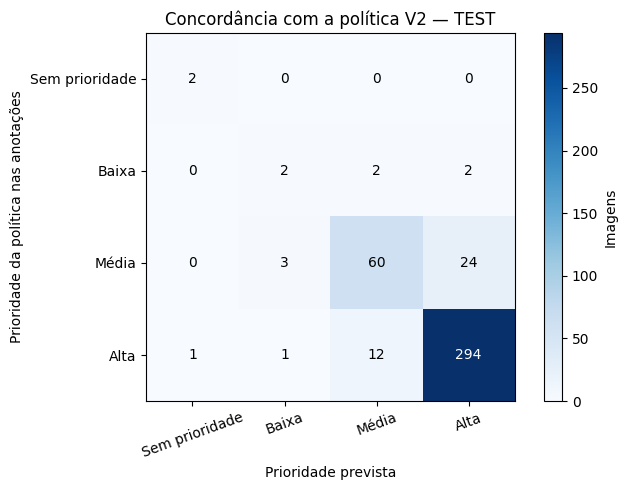

TREINAMENTO E AVALIAÇÃO FINAL COM ALERTAS EM TEXTO
Épocas configuradas: 1
Modelo selecionado na Home VAL: antigo
Confiança dos alertas: 0.25
TEST: 403 imagens, conferidas por SHA-256
Precision detector: 0.6423
Recall detector: 0.6504
mAP@50: 0.6522
mAP@50-95: 0.4461
Alertas comparados com V2 nas anotações; não é validação independente de risco físico.
Uma imagem sem mensagem significa que a política não acionou alerta nas detecções obtidas.

AVALIAÇÃO FINAL E TEXTOS CONCLUÍDOS.
Enviando resultados ao Drive (avaliação final e relatórios)...
Resultados copiados ao Drive.


True

In [16]:
def dividir_ou_nulo(n, d):
    return float(n / d) if d else None


def contagens_alertas(tabela):
    ref = tabela["ha_alerta_ref_politica"].astype(bool)
    prev = tabela["ha_alerta_pred"].astype(bool)
    tp, fn, fp = int((ref & prev).sum()), int((ref & ~prev).sum()), int((~ref & prev).sum())
    return {"tp_vs_politica": tp, "fn_vs_politica": fn, "fp_vs_politica": fp,
            "precision_vs_politica": dividir_ou_nulo(tp, tp + fp),
            "recall_vs_politica": dividir_ou_nulo(tp, tp + fn),
            "f1_vs_politica": dividir_ou_nulo(2 * tp, 2 * tp + fp + fn)}


def resumir_alertas_test(objetos, imagens):
    correspondencias = objetos["evento"].eq("correspondencia")
    mascara = correspondencias & objetos["prioridade_ref_politica"].ne("sem_prioridade")
    alta = objetos["prioridade_ref_politica"].eq("alto")
    return {
        "escopo": "Referência V2 aplicada às anotações; não valida risco físico independentemente",
        "imagens": len(imagens), "objetos_anotados": int(imagens["objetos_gt"].sum()),
        "objetos_previstos": int(imagens["objetos_pred"].sum()),
        "diagnostico_detector_conf_fixa": {
            "tp_iou50_mesma_classe": int(correspondencias.sum()),
            "fn_iou50_mesma_classe": int(objetos["evento"].eq("objeto_nao_detectado").sum()),
            "fp_iou50_mesma_classe": int(objetos["evento"].eq("previsao_nao_associada").sum()),
        },
        "alertas_por_objeto_vs_politica": contagens_alertas(objetos),
        "alertas_por_imagem_vs_politica": contagens_alertas(imagens),
        "concordancia_prioridade_em_objetos_correspondentes": dividir_ou_nulo(
            int(objetos.loc[mascara, "concordancia_prioridade"].eq(True).sum()), int(mascara.sum())),
        "concordancia_prioridade_por_imagem": float(imagens["prioridade_ref_politica"].eq(imagens["prioridade_pred"]).mean()),
        "objetos_prioridade_alta_ref_sem_alerta": int((alta & ~objetos["ha_alerta_pred"].astype(bool)).sum()),
        "tempo_previsao_medio_ms": float(imagens["tempo_previsao_ms"].mean()),
    }


def conferir_test_inalterado(registros, manifesto):
    por_nome = {r["nome"]: r for r in registros}
    for item in manifesto:
        imagem = Path(por_nome[item["imagem"]]["imagem"])
        label = Path(str(imagem).replace("/images/", "/labels/")).with_suffix(".txt")
        if sha256_file(imagem) != item["imagem_sha256"] or sha256_file(label) != item["label_sha256"]:
            raise RuntimeError(f"Imagem ou label TEST alterado durante a avaliação: {item['imagem']}")


DIAGNOSTICO_TEST = resumir_alertas_test(df_objetos_test, df_imagens_test)
DIAGNOSTICO_TEST.update(modelo_selecionado=ESCOLHA_FINAL["modelo"], conf_alerta=CONF_FINAL,
                        test_congelado_sha256=EXPECTED["test_sha256"], test_utilizado_para_selecao=False)
save_json(PASTA_TEST_RESULTADOS / "metricas_alertas_vs_politica.json", DIAGNOSTICO_TEST)
por_classe_alertas = []
for classe in NOMES:
    tabela = df_objetos_test[df_objetos_test["classe_ref"].eq(classe) | df_objetos_test["classe_pred"].eq(classe)]
    por_classe_alertas.append({"classe": classe, **contagens_alertas(tabela)})
pd.DataFrame(por_classe_alertas).to_csv(PASTA_TEST_RESULTADOS / "alertas_por_classe_vs_politica.csv", index=False, encoding="utf-8-sig")

import matplotlib.pyplot as plt
ordem = ["sem_prioridade", "baixo", "medio", "alto"]
matriz = pd.crosstab(df_imagens_test["prioridade_ref_politica"], df_imagens_test["prioridade_pred"])
matriz = matriz.reindex(index=ordem, columns=ordem, fill_value=0)
matriz.to_csv(PASTA_TEST_RESULTADOS / "matriz_prioridade_por_imagem.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7, 5))
cores = ax.imshow(matriz.to_numpy(), cmap="Blues")
rotulos = ["Sem prioridade", "Baixa", "Média", "Alta"]
ax.set_xticks(range(4), rotulos, rotation=20)
ax.set_yticks(range(4), rotulos)
ax.set_xlabel("Prioridade prevista")
ax.set_ylabel("Prioridade da política nas anotações")
ax.set_title("Concordância com a política V2 — TEST")
for linha in range(4):
    for coluna in range(4):
        valor = int(matriz.iloc[linha, coluna])
        cor = "white" if valor > matriz.to_numpy().max() / 2 else "black"
        ax.text(coluna, linha, valor, ha="center", va="center", color=cor)
fig.colorbar(cores, ax=ax, label="Imagens")
fig.tight_layout()
fig.savefig(PASTA_TEST_RESULTADOS / "matriz_prioridade_por_imagem.png", dpi=160)
plt.show()
plt.close(fig)
conferir_test_inalterado(REGISTROS_TEST, MANIFESTO_TEST)
if sha256_file(MODELO_FINAL) != SELECAO_FINAL["modelo_sha256"] or sha256_file(politica.__file__) != SHA_POLITICA:
    raise RuntimeError("Modelo ou política mudou durante a avaliação final.")
CONFIGURACAO["test_avaliado_apos_selecao"] = True
CONFIGURACAO["test_imagens_avaliadas"] = len(REGISTROS_TEST)
save_json(PASTA_RESULTADOS / "configuracao_experimento.json", CONFIGURACAO)
RESUMO_FINAL = {
    "treino_epochs_configuradas": EPOCHS, "openimages_treino": N_OI, "home_train": 1824,
    "home_val": 456, "test": len(REGISTROS_TEST), "selecao_final": SELECAO_FINAL,
    "metricas_detector_test": METRICAS_DETECTOR_TEST, "metricas_alertas_test": DIAGNOSTICO_TEST,
    "test_conferido_sem_alteracoes": True, "textos": str(PASTA_TEST_RESULTADOS / "alertas_texto.txt"),
}
save_json(PASTA_RESULTADOS / "resumo_final.json", RESUMO_FINAL)
resumo_texto = (
    "TREINAMENTO E AVALIAÇÃO FINAL COM ALERTAS EM TEXTO\n"
    f"Épocas configuradas: {EPOCHS}\n"
    f"Modelo selecionado na Home VAL: {ESCOLHA_FINAL['modelo']}\n"
    f"Confiança dos alertas: {CONF_FINAL}\n"
    f"TEST: {len(REGISTROS_TEST)} imagens, conferidas por SHA-256\n"
    f"Precision detector: {METRICAS_DETECTOR_TEST['precision']:.4f}\n"
    f"Recall detector: {METRICAS_DETECTOR_TEST['recall']:.4f}\n"
    f"mAP@50: {METRICAS_DETECTOR_TEST['map50']:.4f}\n"
    f"mAP@50-95: {METRICAS_DETECTOR_TEST['map50_95']:.4f}\n"
    "Alertas comparados com V2 nas anotações; não é validação independente de risco físico.\n"
    "Uma imagem sem mensagem significa que a política não acionou alerta nas detecções obtidas.\n"
)
(PASTA_TEST_RESULTADOS / "resumo.txt").write_text(resumo_texto, encoding="utf-8")
print(resumo_texto)
print("AVALIAÇÃO FINAL E TEXTOS CONCLUÍDOS.")
enviar_resultados_drive("avaliação final e relatórios")


## 13. Avaliar as 20 mil Open Images reservadas

O peso e a confiança continuam congelados pela Home VAL. Uma passagem de inferência em batches calcula AP no recorte parcial e gera as mensagens, com exclusão de classes sem cobertura verificada nas métricas. Caixas anotadas em classes de cobertura desconhecida também ficam fora dessas métricas.

Precision/Recall na confiança final e AP são relatados separadamente. Métricas de alertas por imagem usam apenas imagens com cobertura completa das seis classes que podem gerar alerta; as métricas por objeto usam os pares avaliáveis. Todas as 20 mil imagens aparecem no CSV, com indicação da cobertura. Os textos consideram todas as detecções, inclusive quando não há gabarito suficiente para julgá-las.

Este é um teste interno reservado da seleção Open Images de origem `train`, não o conjunto TEST oficial dessa base. O relatório identifica o método e o número de classes/caixas avaliáveis. Não compara diretamente o AP parcial com o mAP Home nem usa o resultado para mudar o limiar.

Referência do tratamento de cobertura: [protocolo Open Images](https://storage.googleapis.com/openimages/web/evaluation.html).


In [17]:
def conferir_reserva_oi(registros):
    for r in registros:
        for campo, hashcampo in [("imagem", "sha256"), ("label", "label_sha256"), ("cobertura", "cobertura_sha256")]:
            if sha256_file(r[campo]) != r[hashcampo]:
                raise RuntimeError(f"Arquivo da reserva Open Images alterado: {r['oi_id']} / {campo}")


def preparar_registros_oi_teste(reserva, nomes):
    registros = []
    for r in reserva:
        cobertura = json.loads(Path(r["cobertura"]).read_text())
        if cobertura["known_mask"] != r["known_mask"]:
            raise RuntimeError("Cobertura do teste Open Images foi modificada.")
        gt = avaliacao_base.ler_objetos_yolo(r["label"], r["width"], r["height"], nomes)
        registros.append({**r, "largura": r["width"], "altura": r["height"], "gt": gt})
    return registros


def pares_ap_cobertura(gt, pred, limiares):
    """Associação por classe e confiança, com um GT por previsão em cada IoU."""
    correto = np.zeros((len(pred), len(limiares)), dtype=bool)
    matriz = avaliacao_base.iou_matriz(gt, pred)
    ordem = sorted(range(len(pred)), key=lambda pi: (-pred[pi]["confianca"], pi))
    for ti, limiar in enumerate(limiares):
        usados = set()
        for pi in ordem:
            candidatos = [gi for gi, g in enumerate(gt) if gi not in usados
                          and g["classe_id"] == pred[pi]["classe_id"] and matriz[gi, pi] >= limiar]
            if candidatos:
                gi = max(candidatos, key=lambda gi: (matriz[gi, pi], -gi))
                correto[pi, ti] = True
                usados.add(gi)
    return correto


def avaliar_reserva_openimages(modelo, registros, nomes, conf_alerta, batch=16):
    if not registros:
        raise ValueError("Reserva Open Images vazia.")
    limiares = np.linspace(0.50, 0.95, 10)
    linhas_objetos, linhas_imagens, stats = [], [], []
    ignoradas_gt, ignoradas_pred = 0, 0
    # A cobertura completa para métricas por imagem refere-se às seis classes de alerta.
    mascara_alertas = sum(1 << cid for cid, nome in nomes.items() if nome in politica.PESO_OBJETO)
    for inicio in range(0, len(registros), batch):
        bloco = registros[inicio:inicio + batch]
        resultados = list(modelo.predict([str(r["imagem"]) for r in bloco], batch=batch,
                                        conf=0.001, imgsz=640, iou=0.70, max_det=300,
                                        device=0, verbose=False, save=False, stream=True))
        if len(resultados) != len(bloco):
            raise RuntimeError("Inferência retornou quantidade de imagens diferente da reserva.")
        for r, resultado in zip(bloco, resultados):
            if Path(resultado.path).resolve() != Path(r["imagem"]).resolve():
                raise RuntimeError("A ordem da inferência difere do manifesto do teste.")
            todos = objetos_resultado_final(resultado, nomes)
            known = r["known_mask"]
            g_ap = [o for o in r["gt"] if known & (1 << o["classe_id"])]
            p_ap = [o for o in todos if known & (1 << o["classe_id"])]
            ignoradas_gt += len(r["gt"]) - len(g_ap)
            ignoradas_pred += len(todos) - len(p_ap)
            stats.append((pares_ap_cobertura(g_ap, p_ap, limiares),
                          np.asarray([o["confianca"] for o in p_ap], dtype=np.float32),
                          np.asarray([o["classe_id"] for o in p_ap], dtype=int),
                          np.asarray([o["classe_id"] for o in g_ap], dtype=int)))
            pred_texto = adicionar_prioridades([o for o in todos if o["confianca"] >= conf_alerta], r["largura"], r["altura"])
            gt = adicionar_prioridades(g_ap, r["largura"], r["altura"])
            pred = [o for o in pred_texto if known & (1 << o["classe_id"])]
            pares, faltantes, extras = avaliacao_base.corresponder_objetos(gt, pred)
            for gi, pi, iou in pares:
                linhas_objetos.append(linha_objeto(r["nome"], "correspondencia", gi, pi, gt[gi], pred[pi], iou))
            for gi in faltantes:
                linhas_objetos.append(linha_objeto(r["nome"], "objeto_nao_detectado", gi=gi, g=gt[gi]))
            for pi in extras:
                linhas_objetos.append(linha_objeto(r["nome"], "previsao_nao_associada", pi=pi, p=pred[pi]))
            mensagens = mensagens_objetos(pred_texto)
            completo = known & mascara_alertas == mascara_alertas
            linhas_imagens.append({
                "imagem": r["nome"], "id": r["oi_id"], "known_mask": known,
                "objetos_gt_avaliaveis": len(gt), "objetos_gt_sem_cobertura": len(r["gt"]) - len(gt),
                "objetos_pred_avaliaveis_conf_final": len(pred),
                "predicoes_sem_cobertura_conf_final": len(pred_texto) - len(pred),
                "correspondencias": len(pares), "nao_detectados": len(faltantes), "previsoes_nao_associadas": len(extras),
                "prioridade_ref_politica": prioridade_imagem(gt), "prioridade_pred": prioridade_imagem(pred),
                "ha_alerta_ref_politica": any(aciona_alerta(o["prioridade"]) for o in gt),
                "ha_alerta_pred": any(aciona_alerta(o["prioridade"]) for o in pred),
                "avaliavel_por_imagem": completo,
                "mensagem_alerta": "\n".join(mensagens),
            })
        processadas = inicio + len(bloco)
        if processadas % 512 == 0 or processadas == len(registros):
            print(f"Teste Open Images: {processadas:,}/{len(registros):,}", flush=True)
    objetos = pd.DataFrame(linhas_objetos, columns=COLUNAS_OBJETOS_TEST)
    imagens = pd.DataFrame(linhas_imagens)
    tp = np.concatenate([a[0] for a in stats], axis=0)
    scores = np.concatenate([a[1] for a in stats])
    pred_cls = np.concatenate([a[2] for a in stats])
    target_cls = np.concatenate([a[3] for a in stats])
    classes_gt = np.unique(target_cls)
    if len(classes_gt) and len(pred_cls):
        # A versão Ultralytics é a mesma fixada e verificada na etapa 2.
        # P/R ótimos de F1 devolvidos pela rotina não são usados para escolher limiar.
        from ultralytics.utils.metrics import ap_per_class
        retorno = ap_per_class(tp, scores, pred_cls, target_cls, plot=False, names=nomes)
        ap, classes_ap = np.asarray(retorno[5]), np.asarray(retorno[6], dtype=int)
        if ap.shape != (len(classes_ap), 10):
            raise RuntimeError("Formato inesperado do cálculo de AP parcial.")
    else:
        classes_ap, ap = classes_gt, np.zeros((len(classes_gt), 10))
    ap_por_classe = {int(cid): valores for cid, valores in zip(classes_ap, ap)}
    por_classe = []
    for cid, nome in nomes.items():
        vals = ap_por_classe.get(cid)
        tabela = objetos[objetos["classe_ref"].eq(nome) | objetos["classe_pred"].eq(nome)]
        n_tp = int(tabela["evento"].eq("correspondencia").sum())
        n_fn = int(tabela["evento"].eq("objeto_nao_detectado").sum())
        n_fp = int(tabela["evento"].eq("previsao_nao_associada").sum())
        por_classe.append({"classe_id": cid, "classe": nome,
                           "imagens_cobertura_conhecida": sum(bool(r["known_mask"] & (1 << cid)) for r in registros),
                           "caixas_gt_avaliaveis": int((target_cls == cid).sum()),
                           "ap50_parcial": float(vals[0]) if vals is not None else None,
                           "ap50_95_parcial": float(vals.mean()) if vals is not None else None,
                           "tp_conf_final": n_tp, "fn_conf_final": n_fn, "fp_conf_final": n_fp,
                           "precision_conf_final": dividir_ou_nulo(n_tp, n_tp + n_fp),
                           "recall_conf_final": dividir_ou_nulo(n_tp, n_tp + n_fn),
                           **contagens_alertas(tabela)})
    n_tp = int(objetos["evento"].eq("correspondencia").sum())
    n_fn = int(objetos["evento"].eq("objeto_nao_detectado").sum())
    n_fp = int(objetos["evento"].eq("previsao_nao_associada").sum())
    completas = imagens[imagens["avaliavel_por_imagem"]]
    resumo = {
        "imagens": len(imagens), "conf_alertas": conf_alerta,
        "protocolo": "Teste interno de 12 classes com exclusão de classes sem cobertura verificada por imagem",
        "nao_e_metrica_oficial_openimages_challenge": True,
        "map50_parcial": float(ap[:, 0].mean()) if len(ap) else None,
        "map50_95_parcial": float(ap.mean()) if len(ap) else None,
        "classes_com_gt_avaliavel": classes_gt.tolist(),
        "gt_ignorados_sem_cobertura": ignoradas_gt, "predicoes_ignoradas_sem_cobertura_conf_0001": ignoradas_pred,
        "detector_conf_final": {"tp": n_tp, "fn": n_fn, "fp": n_fp,
                                "precision": dividir_ou_nulo(n_tp, n_tp + n_fp),
                                "recall": dividir_ou_nulo(n_tp, n_tp + n_fn)},
        "alertas_por_objeto_com_cobertura": contagens_alertas(objetos),
        "imagens_cobertura_completa_classes_alerta": len(completas),
        "alertas_por_imagem_com_cobertura_completa": contagens_alertas(completas),
        "alta_sem_alerta_com_cobertura": int((objetos["prioridade_ref_politica"].eq("alto") & ~objetos["ha_alerta_pred"].astype(bool)).sum()),
        "textos_gerados_com_todas_deteccoes": True,
        "observacao": "Textos usam todas as detecções acima do limiar. Métricas ignoram classes sem cobertura; ausência de anotação não vira falso positivo.",
    }
    return resumo, pd.DataFrame(por_classe), objetos, imagens


PASTA_OI_TEST_RESULTADOS = PASTA_RESULTADOS / "avaliacao_openimages_reservado"
PASTA_OI_TEST_RESULTADOS.mkdir(parents=True, exist_ok=False)
RESERVA_OI = DADOS["openimages_test"]
if len(RESERVA_OI) != N_OI_TEST or sha256_file(MODELO_FINAL) != SELECAO_FINAL["modelo_sha256"]:
    raise RuntimeError("Reserva ou modelo difere da configuração definida antes dos testes.")
conferir_reserva_oi(RESERVA_OI)
REGISTROS_OI_TEST = preparar_registros_oi_teste(RESERVA_OI, NOMES_DICT)
METRICAS_OI_TEST, CLASSES_OI_TEST, OBJETOS_OI_TEST, IMAGENS_OI_TEST = avaliar_reserva_openimages(
    modelo_final, REGISTROS_OI_TEST, NOMES_DICT, CONF_FINAL, batch=BATCH,
)
METRICAS_OI_TEST.update(modelo_selecionado=ESCOLHA_FINAL["modelo"],
                       modelo_sha256=SELECAO_FINAL["modelo_sha256"],
                       divisao_sha256=DADOS["divisao_openimages_sha256"],
                       usado_para_selecao=False, reservado_antes_treino=True)
save_json(PASTA_OI_TEST_RESULTADOS / "metricas_openimages_parcial.json", METRICAS_OI_TEST)
CLASSES_OI_TEST.to_csv(PASTA_OI_TEST_RESULTADOS / "metricas_por_classe.csv", index=False, encoding="utf-8-sig")
OBJETOS_OI_TEST.to_csv(PASTA_OI_TEST_RESULTADOS / "avaliacao_objetos_com_cobertura.csv", index=False, encoding="utf-8-sig")
IMAGENS_OI_TEST.to_csv(PASTA_OI_TEST_RESULTADOS / "alertas_por_imagem.csv", index=False, encoding="utf-8-sig")
blocos_oi = [f"{r['imagem']}\n{r['mensagem_alerta']}" for r in IMAGENS_OI_TEST.to_dict("records") if r["mensagem_alerta"]]
(PASTA_OI_TEST_RESULTADOS / "alertas_texto.txt").write_text("\n\n".join(blocos_oi), encoding="utf-8")
conferir_reserva_oi(RESERVA_OI)
if sha256_file(politica.__file__) != SHA_POLITICA or sha256_file(MODELO_FINAL) != SELECAO_FINAL["modelo_sha256"]:
    raise RuntimeError("Modelo ou política mudou durante o teste Open Images.")
RESUMO_FINAL["teste_openimages_reservado"] = METRICAS_OI_TEST
RESUMO_FINAL["divisao_openimages_sha256"] = DADOS["divisao_openimages_sha256"]
CONFIGURACAO["openimages_teste_avaliado_apos_selecao"] = True
save_json(PASTA_RESULTADOS / "resumo_final.json", RESUMO_FINAL)
save_json(PASTA_RESULTADOS / "configuracao_experimento.json", CONFIGURACAO)
print(json.dumps(METRICAS_OI_TEST, ensure_ascii=False, indent=2))
display(CLASSES_OI_TEST)
print("TESTE OPEN IMAGES RESERVADO E TEXTOS CONCLUÍDOS.")
enviar_resultados_drive("teste reservado Open Images e textos")


Teste Open Images: 512/20,000
Teste Open Images: 1,024/20,000
Teste Open Images: 1,536/20,000
Teste Open Images: 2,048/20,000
Teste Open Images: 2,560/20,000
Teste Open Images: 3,072/20,000
Teste Open Images: 3,584/20,000
Teste Open Images: 4,096/20,000
Teste Open Images: 4,608/20,000
Teste Open Images: 5,120/20,000
Teste Open Images: 5,632/20,000
Teste Open Images: 6,144/20,000
Teste Open Images: 6,656/20,000
Teste Open Images: 7,168/20,000
Teste Open Images: 7,680/20,000
Teste Open Images: 8,192/20,000
Teste Open Images: 8,704/20,000
Teste Open Images: 9,216/20,000
Teste Open Images: 9,728/20,000
Teste Open Images: 10,240/20,000
Teste Open Images: 10,752/20,000
Teste Open Images: 11,264/20,000
Teste Open Images: 11,776/20,000
Teste Open Images: 12,288/20,000
Teste Open Images: 12,800/20,000
Teste Open Images: 13,312/20,000
Teste Open Images: 13,824/20,000
Teste Open Images: 14,336/20,000
Teste Open Images: 14,848/20,000
Teste Open Images: 15,360/20,000
Teste Open Images: 15,872/20,00

,classe_id,classe,imagens_cobertura_conhecida,caixas_gt_avaliaveis,ap50_parcial,ap50_95_parcial,tp_conf_final,fn_conf_final,fp_conf_final,precision_conf_final,recall_conf_final,tp_vs_politica,fn_vs_politica,fp_vs_politica,precision_vs_politica,recall_vs_politica,f1_vs_politica
0,0,bed,1009,443,0.622782,0.365499,252,191,74,0.773006,0.568849,251,183,73,0.774691,0.578341,0.662269
1,1,sofa,1133,538,0.484874,0.261928,385,153,562,0.406547,0.715613,361,125,506,0.416378,0.742798,0.533629
2,2,chair,4629,19816,0.385053,0.189646,6793,13023,3751,0.644253,0.342804,5366,8079,2868,0.651688,0.399107,0.495041
3,3,table,8090,12771,0.421106,0.203603,5359,7412,4201,0.560565,0.419623,4839,5269,3531,0.578136,0.478730,0.523758
4,4,lamp,247,425,0.127616,0.040626,63,362,112,0.360000,0.148235,0,0,0,NaN,NaN,NaN
5,5,tv,537,664,0.316244,0.197369,140,524,46,0.752688,0.210843,0,0,0,NaN,NaN,NaN
6,6,laptop,1747,1704,0.127892,0.058982,242,1462,456,0.346705,0.142019,0,0,0,NaN,NaN,NaN
7,7,wardrobe,438,0,NaN,NaN,0,0,97,0.000000,NaN,0,0,90,0.000000,NaN,0.000000
8,8,window,7230,38839,0.070397,0.031553,2053,36786,3230,0.388605,0.052859,0,0,0,NaN,NaN,NaN
9,9,door,3602,3570,0.181476,0.090431,637,2933,866,0.423819,0.178431,0,0,0,NaN,NaN,NaN


TESTE OPEN IMAGES RESERVADO E TEXTOS CONCLUÍDOS.
Enviando resultados ao Drive (teste reservado Open Images e textos)...
Resultados copiados ao Drive.


True

## 14. Demonstrar em uma imagem nova — opcional

Para testar depois com uma imagem disponível no Kaggle, informe seu caminho em `IMAGEM_NOVA`. Esta demonstração não entra nas métricas TEST e usa o mesmo peso, política e confiança já definidos. Com `None`, a execução completa segue normalmente.


In [18]:
IMAGEM_NOVA = None  # Exemplo: Path("/kaggle/input/minhas-imagens/sala.jpg")
if IMAGEM_NOVA is not None:
    imagem_nova = Path(IMAGEM_NOVA)
    if not imagem_nova.is_file():
        raise FileNotFoundError(imagem_nova)
    with Image.open(imagem_nova) as im:
        largura, altura = im.size
    resultado_novo = modelo_final.predict(str(imagem_nova), conf=CONF_FINAL, imgsz=640, iou=0.70,
                                         max_det=300, device=0, verbose=False, save=False)[0]
    objetos_novos = adicionar_prioridades(objetos_resultado_final(resultado_novo, NOMES_DICT), largura, altura)
    mensagens_novas = mensagens_objetos(objetos_novos)
    texto_novo = "\n".join(mensagens_novas) if mensagens_novas else "Nenhum alerta acionado pelas regras configuradas."
    (PASTA_TEST_RESULTADOS / "demonstracao_imagem_nova.txt").write_text(texto_novo, encoding="utf-8")
    print(texto_novo)


## 15. Salvar todos os resultados no Google Drive

A pasta é `Meu Drive/TCC_Visao_Computacional/resultados/<experimento>`. A cópia também fica na saída do Kaggle em `/kaggle/working/resultados_tcc/<experimento>`.

Arquivos principais:

- `divisao_openimages.json` e `divisao_openimages.csv`: reserva fixa de treino/teste.
- `distribuicao_divisao_openimages.csv`: contagens por classe e cobertura.
- `avaliacao_openimages_reservado/metricas_openimages_parcial.json`: métricas das 20 mil reservadas.
- `avaliacao_openimages_reservado/alertas_por_imagem.csv` e `alertas_texto.txt`: resultados e textos da reserva.
- `best.pt`: candidato treinado na única época.
- `modelo_selecionado.pt` e `selecao_final.json`: peso e confiança definidos na Home VAL.
- `configuracao_experimento.json`, `resumo_dados_treino.json`, `treinamento/results.csv`: treino e dados usados.
- `comparacao_validacao.csv` e a pasta `calibracao_confianca_...`: comparação e calibração.
- `avaliacao_final_test/metricas_detector.csv` e `metricas_detector_por_classe.csv`: detecção no TEST.
- `avaliacao_final_test/metricas_alertas_vs_politica.json`: resultado dos alertas.
- `avaliacao_final_test/avaliacao_objetos.csv` e `alertas_por_imagem.csv`: diagnóstico detalhado.
- `avaliacao_final_test/alertas_texto.txt`: mensagens geradas.
- `resumo_final.json` e `avaliacao_final_test/resumo.txt`: consolidação da execução.

O envio final abaixo é obrigatório para a execução ser marcada como concluída por este notebook. Se o Kaggle interromper a sessão, os checkpoints já enviados preservam o trabalho realizado. Reexecutar o notebook inteiro cria um novo experimento e realiza novamente a única época.


In [19]:
enviar_resultados_drive("envio final: treino, TEST e mensagens em texto", obrigatorio=True)
print("NOTEBOOK 10 CONCLUÍDO — TREINO 80/20 DE UMA ÉPOCA, DOIS TESTES E TEXTOS SALVOS.")
print("Resultados locais:", PASTA_RESULTADOS)
print("Resultados no Drive:", f"{ORIGEM_DRIVE}/resultados/{NOME_EXPERIMENTO}")
print("Modelo selecionado:", ESCOLHA_FINAL["modelo"], "| confiança:", CONF_FINAL)
print("Mensagens:", PASTA_TEST_RESULTADOS / "alertas_texto.txt")
print("Reserva Open Images:", N_OI_TEST, "| resultados:", PASTA_OI_TEST_RESULTADOS)


Enviando resultados ao Drive (envio final: treino, TEST e mensagens em texto)...
Resultados copiados ao Drive.
NOTEBOOK 10 CONCLUÍDO — TREINO 80/20 DE UMA ÉPOCA, DOIS TESTES E TEXTOS SALVOS.
Resultados locais: /kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010
Resultados no Drive: gdrive_tcc:TCC_Visao_Computacional/resultados/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010
Modelo selecionado: antigo | confiança: 0.25
Mensagens: /kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/avaliacao_final_test/alertas_texto.txt
Reserva Open Images: 20000 | resultados: /kaggle/working/resultados_tcc/yolov8n_home_openimages_80_20_1ep_kaggle_20261015_030228_068010/avaliacao_openimages_reservado
